# DX703 Final Project Milestone: Data Exploration and Baseline Modeling

### Due Date: Sunday, November 15th at 11:59pm (with 2 hour plus 1 minute grace period)

**No late submissions!**


## Purpose and scope

This is the **first of two project submissions**. Choose **one** classification dataset—**Food-101** (images) or **HuffPost News Category** (text)—and carry it from initial exploration through a reproducible **baseline model**.

In this milestone you will:

1. Explore both datasets briefly; select and investigate one (**10 pts**).
2. Frame its classification problem, challenges, and evaluation strategy (**15 pts**).
3. Clean and preprocess your data and create reproducible train/validation/test splits (**30 pts**).
4. Train and evaluate a simple baseline using **training and validation data only** (**30 pts**).

**The later final submission** will cover a more capable custom model, a pretrained/transfer-learning model, comparison and selection, a refined final model, and the final technical report. Details of that submission will be posted separately.

### Important conventions

- Retain your chosen dataset for the entire project. Remove the unused dataset's starter cells **after** exploring both.
- Use a fixed random seed, state all data-selection choices and important hyperparameters, and keep the notebook runnable from top to bottom.
- You may use a documented, reproducible subset for experiments if computing resources are limited; explain its size and selection process. Do not represent subset performance as full-dataset performance.
- **Keep the test set untouched in this milestone.** Select models and discuss baseline performance using *validation* results. Save test-set evaluation for the final submission.
- Write each graded explanation in its designated Python string answer variable (`a1a`, `a1b`, etc.). Do not modify the following **Graded Answer** print cells. You may add code cells, plots, or comments as necessary. Follow the approximate word-count guidelines in each problem (100–150 words for Problems 1, 3, and 4; 75–125 words for Problem 2).
- Include an AI-use disclosure at the end in accordance with CDS policy.


### Grading — 85 points total

| Problem | Grading basis | Points |
|---|---|---:|
| 1. Choose the Dataset | 5 questions × 2 pts, including supporting code, tables, and plots | **10** |
| 2. Frame the Problem | 5 questions × 3 pts, including supporting evidence | **15** |
| 3. Data Preparation and Splits | Programming: 18 pts; 4 written answers × 3 pts | **30** |
| 4. Baseline Model | Programming: 18 pts; 4 written answers × 3 pts | **30** |
| **Total** | | **85** |

**How your work will be assessed:** For Problems 1–2, each question will be assessed as a whole, including your written response and the supporting code, tables, or plots. For Problems 3–4, programming and written answers receive separate point allocations.

Programming will be assessed primarily for **correctness and completeness**, with attention to reproducibility, organization, and clarity. Written answers should accurately explain *your own implementation and results*, referring to specific evidence from the notebook. Code may be reviewed and tested, so explanations alone do not earn programming credit. Your submitted notebook must run from beginning to end without errors.

**Use of AI in grading:** We will use AI tools to assist with reviewing code, evaluating written responses, and identifying possible errors or omissions. However, **AI will not make final grading decisions. Every proposed point deduction will be reviewed by a human grader before it is applied.** Human graders retain responsibility for determining and assigning final scores.

In [1]:
# ============================================
# Useful Imports
# ============================================

# --- Standard Libraries
import os
import time
import math
import random
from collections import Counter

# --- Core Data / Numerics
import numpy as np
import pandas as pd

# --- Visualization
import matplotlib.pyplot as plt
# import seaborn as sns              # optional
import matplotlib.ticker as mticker  # optional (for formatted axes)

# --- NLP / Tokenization
import spacy                         # used for text preprocessing (HuffPost)

# --- Progress Tracking
from tqdm import tqdm                # optional (nice for loops)

from IPython.display import display

# --- TensorFlow / Keras (Deep Learning)
import tensorflow as tf
from tensorflow.keras import layers, models, Input, callbacks, regularizers, initializers
from tensorflow.keras.callbacks import Callback, EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.optimizers import Adam, AdamW
from tensorflow.keras.optimizers.schedules import CosineDecay, ExponentialDecay
from tensorflow.keras.preprocessing.image import ImageDataGenerator, load_img, img_to_array
from tensorflow.keras.layers import (
    Dense, Dropout, Flatten, MaxPooling2D, Conv2D,
    SeparableConv2D, GlobalAveragePooling2D, GlobalMaxPooling2D, BatchNormalization
)

# --- (Optional) Classical ML Baseline Tools
# from sklearn.pipeline import Pipeline
# from sklearn.feature_extraction.text import TfidfVectorizer
# from sklearn.linear_model import LogisticRegression
# from sklearn.metrics import accuracy_score


# ============================================
# Global Configuration & Small Utilities
# ============================================

# Reproducibility
random_seed = 42
random.seed(random_seed)
np.random.seed(random_seed)
tf.keras.utils.set_random_seed(random_seed)   # sets Python, NumPy, and TensorFlow seeds

# Utility: format seconds as HH:MM:SS

"""
Example usage to time your code:

start_time = time.time()
# ... your code here ...
print("Execution Time:", format_hms(time.time() - start_time))
"""

def format_hms(seconds: float) -> str:
    """Convert seconds to HH:MM:SS format."""
    return time.strftime("%H:%M:%S", time.gmtime(seconds))


/home/caleb/miniconda3/envs/tf_gpu/lib/python3.12/site-packages/requests/__init__.py:92: RequestsDependencyWarning: Unable to find acceptable character detection dependency (chardet or charset_normalizer).
  warnings.warn(
I0000 00:00:1794685586.994680   58805 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794685587.032319   58805 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1794685587.922695   58805 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different compu

In [2]:
# If needed (in a new env):
# !pip install -U datasets pillow

In [3]:
# --- Hugging Face Datasets
from datasets import load_dataset, DatasetDict
from datasets.features import ClassLabel

### Dataset One (Images): Food-101

#### **Load Food-101 as a Dataset**

> Note: this loads a **Hugging Face `Dataset`**, not NumPy or TensorFlow tensors.
> Each sample is stored as a **dictionary** with two keys — `"image"` (a PIL image object) and `"label"` (an integer class ID).
> You can access columns by name, e.g. `food_all["image"]` or `food_all["label"]`, and check the dataset size with `len(food_all)`.
> Unlike arrays, image sizes and aspect ratios may differ across samples — you’ll handle resizing or normalization later during preprocessing.


In [4]:
food_all = load_dataset("ethz/food101", split="train+validation")  # ~101k images total
label_col = "label"

# Sanity check the label column
assert label_col in food_all.features
assert isinstance(food_all.features[label_col], ClassLabel)

food_label_names = food_all.features[label_col].names
print(f"Total images: {len(food_all):,}  |  Classes: {len(food_label_names)}")

Total images: 101,000  |  Classes: 101


#### **Quick sanity checks (rows, label ids, a few image sizes)**

In [5]:
# First 5 rows: label id → name
for i in range(5):
    y = food_all[i][label_col]
    print(f"row {i}: id={y}, name={food_label_names[y]}")

labels_list = list(food_all[label_col])
print("labels length:", len(labels_list), "unique classes:", len(set(labels_list)))
print("min/max label IDs:", min(labels_list), max(labels_list))

for i in range(3):
    print(f"image {i} size:", food_all[i]["image"].size)  # (W, H)

row 0: id=6, name=beignets
row 1: id=6, name=beignets
row 2: id=6, name=beignets
row 3: id=6, name=beignets
row 4: id=6, name=beignets
labels length: 101000 unique classes: 101
min/max label IDs: 0 100
image 0 size: (384, 512)
image 1 size: (512, 512)
image 2 size: (512, 383)


#### **Visual preview: random 3×3 grid from TRAIN**

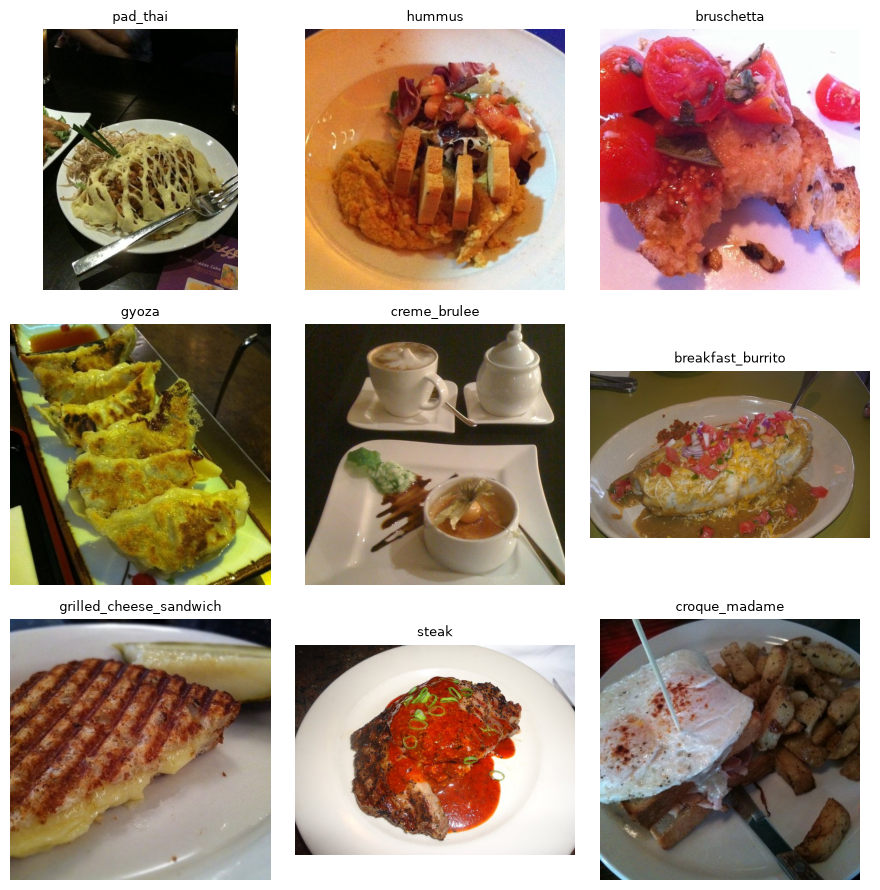

In [6]:
n, cols, seed = 9, 3, 42
idxs = random.Random(seed).sample(range(len(food_all)), n)
rows = math.ceil(n/cols)

plt.figure(figsize=(3*cols, 3*rows))
for i, idx in enumerate(idxs, 1):
    ex = food_all[idx]
    plt.subplot(rows, cols, i)
    plt.imshow(ex["image"]); plt.axis("off")
    plt.title(food_label_names[ex[label_col]], fontsize=9)
plt.tight_layout(); plt.show()

---

## Problem 1 — Choose the Dataset (10 pts)

#### Objective
In this problem, you will explore the two provided datasets and select one to use for your final project.  
Your goal is to understand the structure, content, and challenges of the dataset through basic exploratory data analysis (EDA).  
By the end of this milestone notebook, you should be able to explain what makes the dataset interesting, identify potential modeling challenges (e.g., imbalance, ambiguity, quality issues), and justify why it is a good choice for your classification project.


#### What to Do
1. **Load both datasets** and examine the outputs of the template code provided.  
   After this brief inspection, **choose one dataset for your project** and **delete the template code for the other.**  For your chosen dataset, continue with the remaining steps.

2. **Inspect** the dataset's basic properties:  
   - **Number of samples and classes:**  
     Determine how many total examples and distinct categories are present. Verify that the counts match expectations (e.g., 101 food classes or 41 news topics).  
   - **Example records or images:**  
     View several samples to understand the input format, diversity, and potential quality issues.  
     For images, note lighting or composition differences; for text, read a few headlines and summaries to see how expressive they are (done for you in template code). 
   - **Distribution of labels (check for imbalance):**  
     Plot or tabulate label frequencies to see whether some classes dominate. Imbalanced datasets can bias model training and may require special handling.  
   - **Missing or inconsistent data:**  
     Look for empty fields, unreadable images, duplicate entries, or mislabeled samples. Handle or document any issues you find.  
   - **Overlapping or ambiguous class labels:**  
     Identify categories that may not be clearly distinct—e.g., “apple pie” vs. “cheesecake,” or “POLITICS” vs. “WORLD NEWS.”  
     Ambiguity in labels can increase confusion between classes and reduce model accuracy.

3. **Visualize key aspects:**  
   Extend the template code to complete the EDA for your chosen dataset:  
   - **Images:**  
     Create visual summaries to better understand the data (some are implemented in the template code).  
     - Verify that the dataset is balanced across classes.  
     - Display a small grid of random images to check variation in appearance, composition, and background (done in template code).  
     - Compare image sizes to determine whether resizing or normalization will be needed.  
     - Examine lighting and color balance—many web-scraped photos vary widely in brightness, saturation, and white balance.  
   - **Text:**  
     Visualize class balance and linguistic properties (some implemented in the template code).  
     - Plot the number of samples per label to confirm class balance or imbalance.  
     - Compute basic text statistics such as average word count or vocabulary size.  
     - Examine examples for duplicates, near-duplicates, or entries that might fit multiple categories.  
     - *(Optional)* Generate a word-frequency plot or word cloud to highlight distinctive terms for a few classes.

4. **Answer the graded questions below.**


#### 1. Template Code for Image Dataset

##### **Quick sanity checks (rows, label ids, a few image sizes)**

In [7]:
# First 5 rows: label id → name
for i in range(5):
    y = food_all[i][label_col]
    print(f"row {i}: id={y}, name={food_label_names[y]}")

labels_list = list(food_all[label_col])
print("labels length:", len(labels_list), "unique classes:", len(set(labels_list)))
print("min/max label IDs:", min(labels_list), max(labels_list))

for i in range(3):
    print(f"image {i} size:", food_all[i]["image"].size)  # (W, H)

row 0: id=6, name=beignets
row 1: id=6, name=beignets
row 2: id=6, name=beignets
row 3: id=6, name=beignets
row 4: id=6, name=beignets
labels length: 101000 unique classes: 101
min/max label IDs: 0 100
image 0 size: (384, 512)
image 1 size: (512, 512)
image 2 size: (512, 383)


##### **Visual preview: random 3×3 grid from TRAIN**

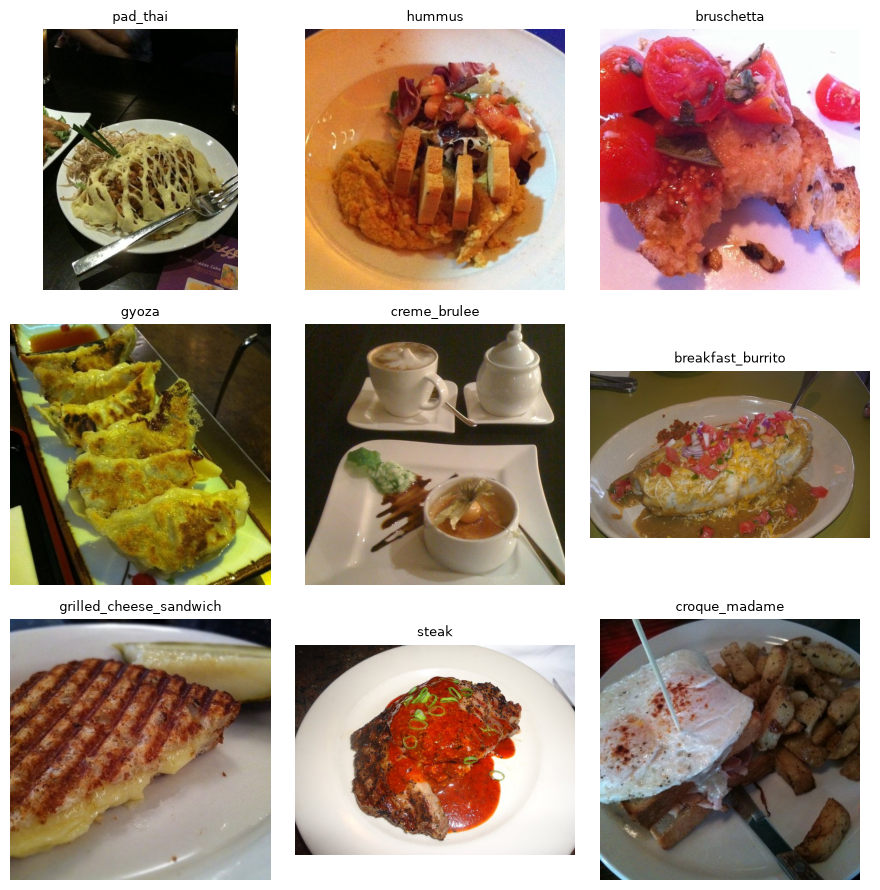

In [8]:
n, cols, seed = 9, 3, 42
idxs = random.Random(seed).sample(range(len(food_all)), n)
rows = math.ceil(n/cols)

plt.figure(figsize=(3*cols, 3*rows))
for i, idx in enumerate(idxs, 1):
    ex = food_all[idx]
    plt.subplot(rows, cols, i)
    plt.imshow(ex["image"]); plt.axis("off")
    plt.title(food_label_names[ex[label_col]], fontsize=9)
plt.tight_layout(); plt.show()

#### 2. Inspect the dataset's basic properties:  

##### Number of samples and classes

Determine how many total examples and distinct categories are present. Verify that the counts match expectations (e.g., 101 food classes or 41 news topics).  

In [9]:
len(food_all)

101000

In [10]:
np.unique(food_all['label'])

array([  0,   1,   2,   3,   4,   5,   6,   7,   8,   9,  10,  11,  12,
        13,  14,  15,  16,  17,  18,  19,  20,  21,  22,  23,  24,  25,
        26,  27,  28,  29,  30,  31,  32,  33,  34,  35,  36,  37,  38,
        39,  40,  41,  42,  43,  44,  45,  46,  47,  48,  49,  50,  51,
        52,  53,  54,  55,  56,  57,  58,  59,  60,  61,  62,  63,  64,
        65,  66,  67,  68,  69,  70,  71,  72,  73,  74,  75,  76,  77,
        78,  79,  80,  81,  82,  83,  84,  85,  86,  87,  88,  89,  90,
        91,  92,  93,  94,  95,  96,  97,  98,  99, 100])

In [11]:
len(np.unique(food_all['label']))

101

There are 101,000 instances and 101 classes

##### **Example records or images:**  
View several samples to understand the input format, diversity, and potential quality issues.  
For images, note lighting or composition differences; for text, read a few headlines and summaries to see how expressive they are (done for you in template code). 

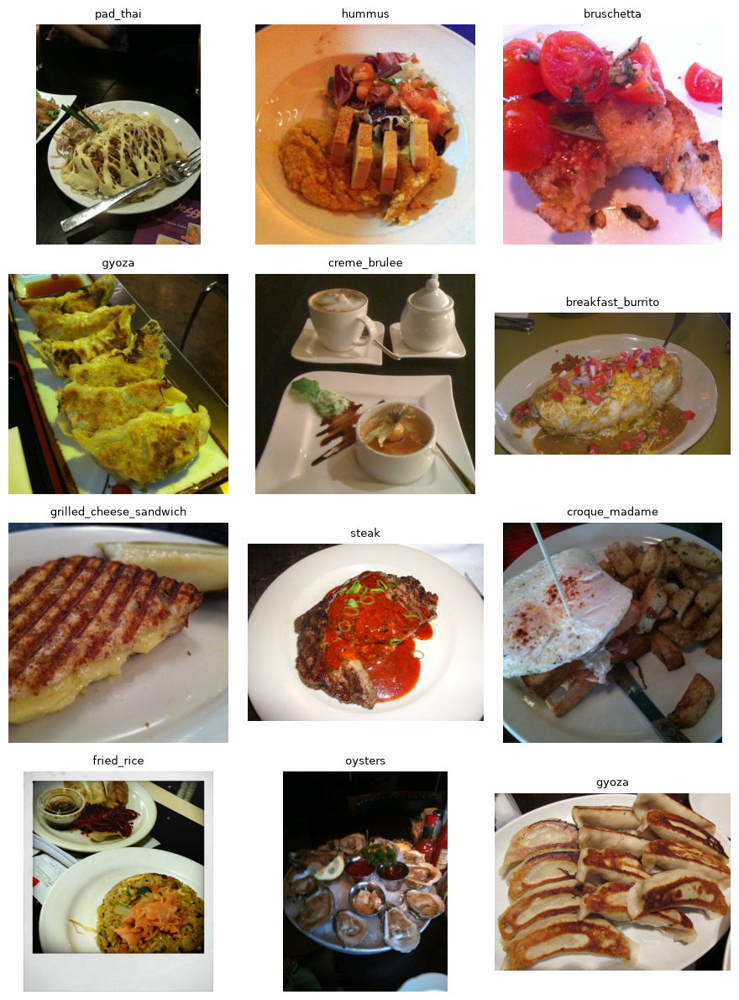

In [12]:
n, cols, seed = 12, 3, 42
idxs = random.Random(seed).sample(range(len(food_all)), n)
rows = math.ceil(n/cols)

plt.figure(figsize=(3*cols, 3*rows))
for i, idx in enumerate(idxs, 1):
    ex = food_all[idx]
    plt.subplot(rows, cols, i)
    plt.imshow(ex["image"]); plt.axis("off")
    plt.title(food_label_names[ex[label_col]], fontsize=9)
plt.tight_layout(); plt.show()

We can see there is variance in:
- Lighting
- Composition (distance from food, plate shape/type, background, and silverware presence)

##### **Distribution of labels (check for imbalance):**  
Plot or tabulate label frequencies to see whether some classes dominate. Imbalanced datasets can bias model training and may require special handling.  

In [13]:
label_counts = pd.Series(food_all['label']).value_counts()
label_counts

6     1000
79    1000
81    1000
53    1000
10    1000
      ... 
12    1000
62    1000
50    1000
71    1000
90    1000
Name: count, Length: 101, dtype: int64

In [14]:
all(label_counts == 1_000)

True

There is no class imbalance. Each label has 1,000 instances, giving a total of 101 * 1,000 = 101,000 total instances. This matches out previous total number of instances in the dataset

##### **Missing or inconsistent data:**  
Look for empty fields, unreadable images, duplicate entries, or mislabeled samples. Handle or document any issues you find.  

- There are no missing values
- We identify 8 duplicates and removed them accordingly
- We discovered some images are not food items (menus) and have invalid labels. We cannot remove all of these due to dataset size
- I could not determine which images are unreadable due to dataset size
- I could not determine which samples are mislabeled outside the duplicates due to dataset size

In [15]:
for column in food_all.column_names:
    # Use .with_format("arrow") to keep it memory-mapped
    arrow_table = food_all.with_format("arrow")[:]
    null_count = arrow_table[column].null_count
    print(f"Column '{column}': Missing Value Count: {null_count}")

Column 'image': Missing Value Count: 0
Column 'label': Missing Value Count: 0


In [16]:
from collections import Counter
import hashlib

images = arrow_table["image"].to_pylist()

keys = [
    ("bytes", hashlib.sha256(img["bytes"]).hexdigest())
    if img and img.get("bytes") is not None
    else ("path", img.get("path")) if img else None
    for img in images
]

counts = Counter(key for key in keys if key is not None)

print("Duplicate rows beyond the first:", sum(n - 1 for n in counts.values() if n > 1))
print("Number of duplicated images:", sum(n > 1 for n in counts.values()))

Duplicate rows beyond the first: 8
Number of duplicated images: 8



Duplicate group 1 — rows [1395, 18114]
  Row 1395: label=prime_rib, path=76271.jpg


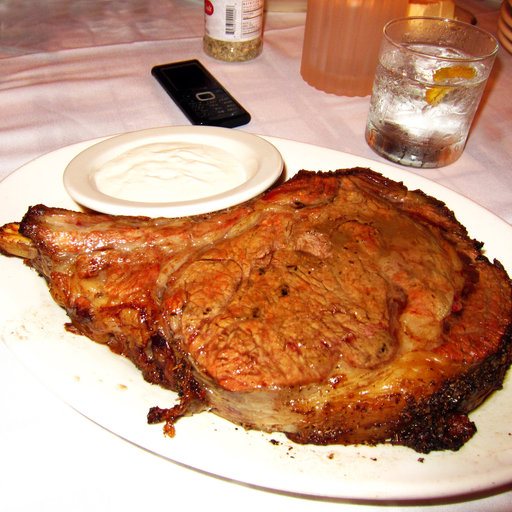

  Row 18114: label=steak, path=97656.jpg


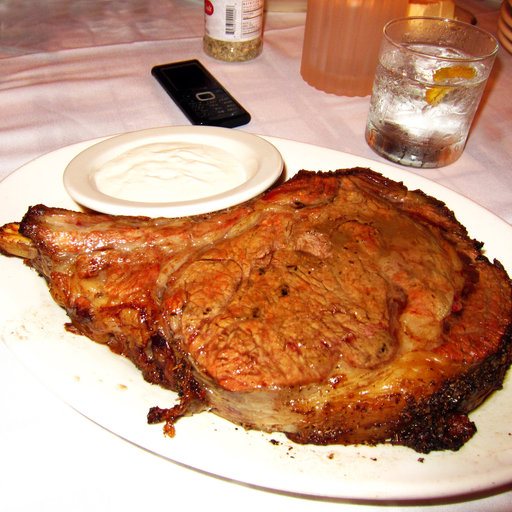


Duplicate group 2 — rows [2781, 2982]
  Row 2781: label=hamburger, path=3578279.jpg


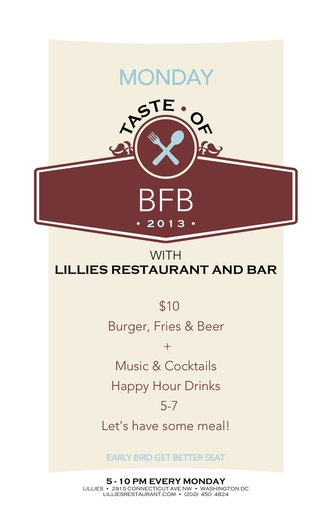

  Row 2982: label=hamburger, path=3783650.jpg


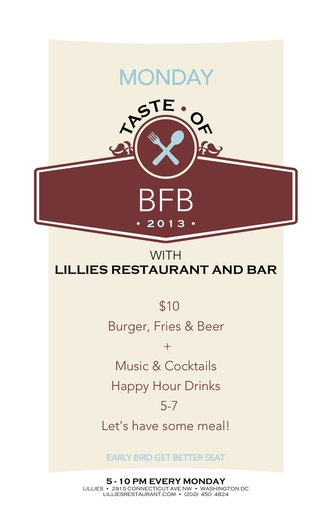


Duplicate group 3 — rows [22486, 59684]
  Row 22486: label=pancakes, path=2619752.jpg


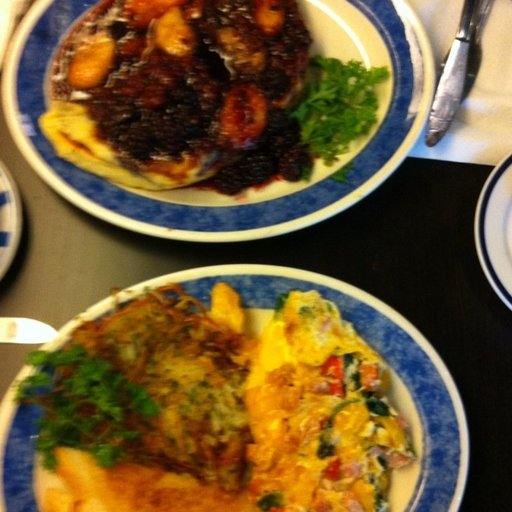

  Row 59684: label=omelette, path=2619753.jpg


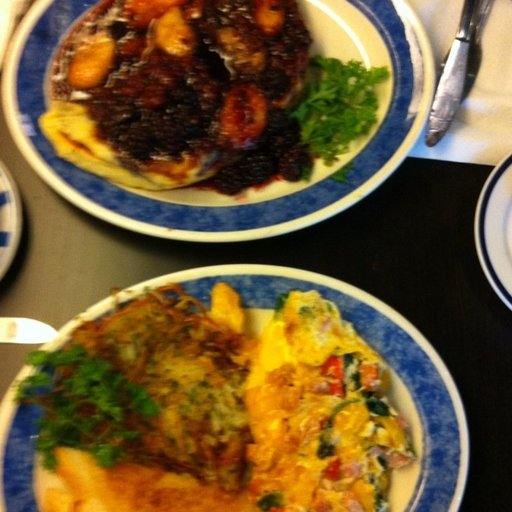


Duplicate group 4 — rows [35554, 35932]
  Row 35554: label=dumplings, path=180290.jpg


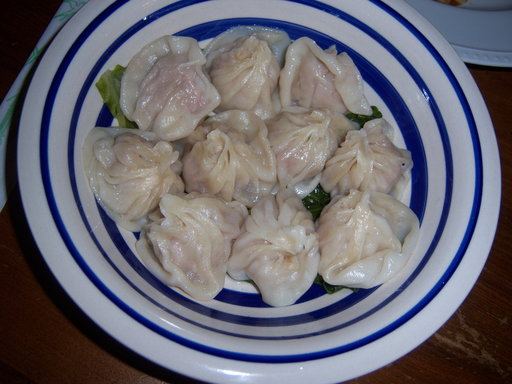

  Row 35932: label=dumplings, path=167000.jpg


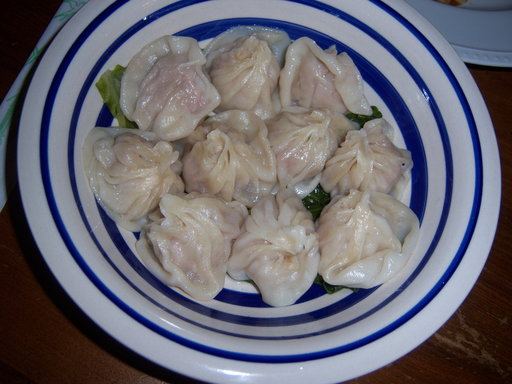


Duplicate group 5 — rows [50531, 50919]
  Row 50531: label=pho, path=51122.jpg


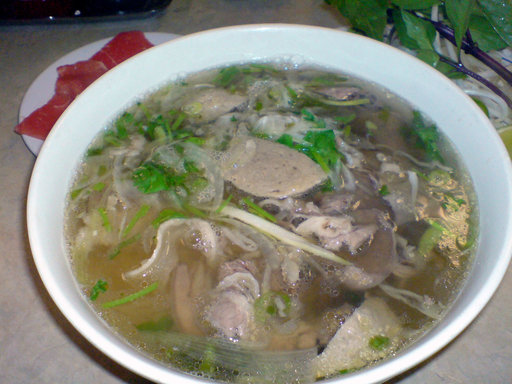

  Row 50919: label=pho, path=651427.jpg


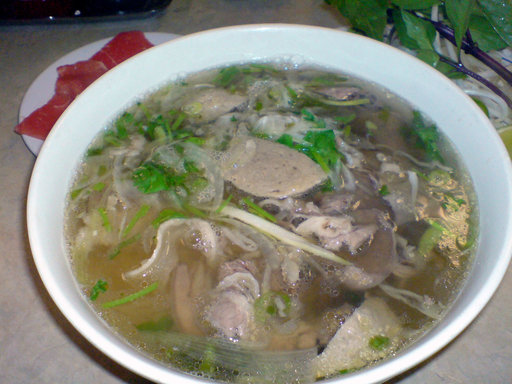


Duplicate group 6 — rows [50881, 50980]
  Row 50881: label=pho, path=4787.jpg


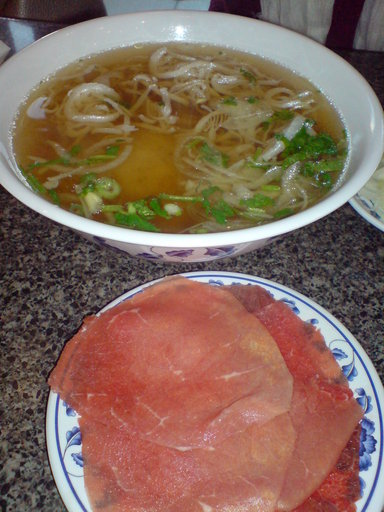

  Row 50980: label=pho, path=51112.jpg


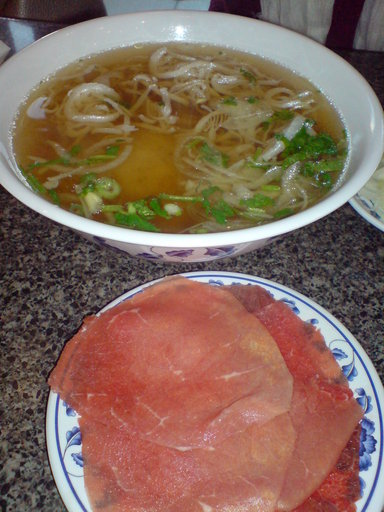


Duplicate group 7 — rows [71491, 99649]
  Row 71491: label=churros, path=2547960.jpg


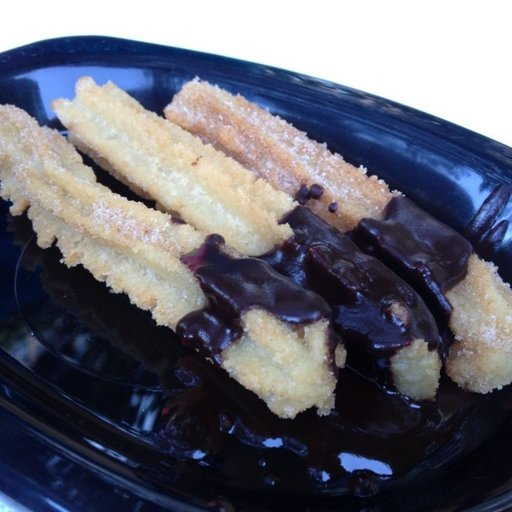

  Row 99649: label=churros, path=2617186.jpg


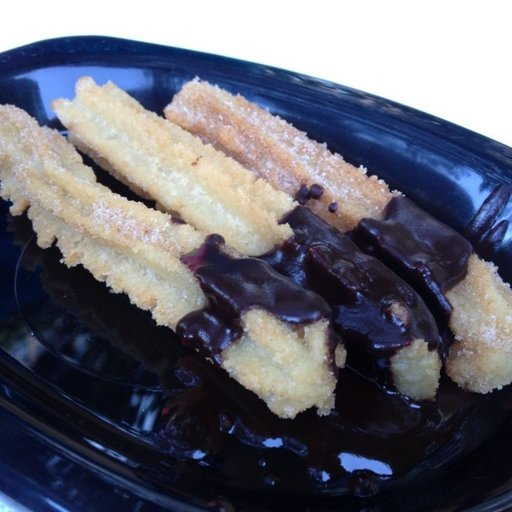


Duplicate group 8 — rows [74819, 100572]
  Row 74819: label=paella, path=2199941.jpg


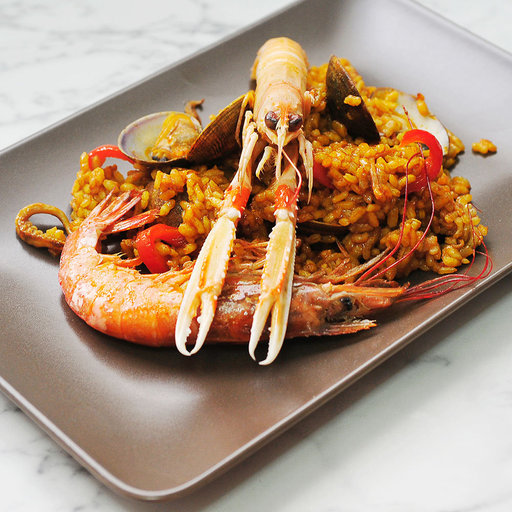

  Row 100572: label=paella, path=2199939.jpg


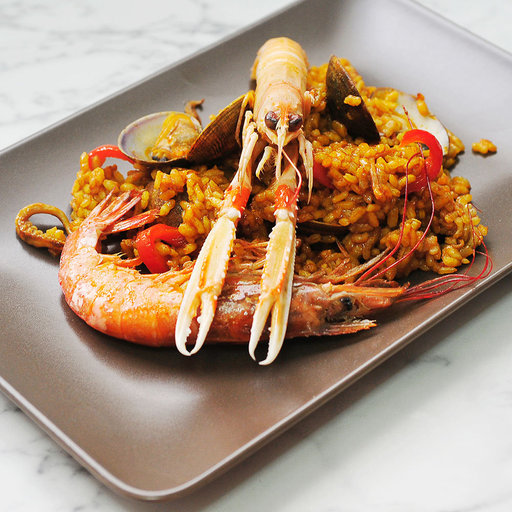

In [17]:
from collections import defaultdict
from io import BytesIO
from PIL import Image as PILImage
from IPython.display import display

groups = defaultdict(list)
for index, key in enumerate(keys):
    if key is not None:
        groups[key].append(index)

labels = arrow_table["label"].to_pylist()
duplicate_groups = [indices for indices in groups.values() if len(indices) > 1]

for group_num, indices in enumerate(duplicate_groups, start=1):
    print(f"\nDuplicate group {group_num} — rows {indices}")

    for index in indices:
        img = images[index]
        # print(f"  Row {index}: label={labels[index]!r}, path={img.get('path')}")
        print(f"  Row {index}: label={food_label_names[labels[index]]}, path={img.get('path')}")
        if img.get("bytes") is not None:
            display(PILImage.open(BytesIO(img["bytes"])))

In [18]:
# Remove one row from each duplicate group after manual review.
indices_to_remove = {
    18114,  # Keep the first; both prime_rib and steak are valid labels.
    2781,   # Menu photo, not food; hamburger label is incorrect.
    2982,   # Menu photo, not food; hamburger label is incorrect.
    22486,  # Keep the omelette-labeled image; pancake label is incorrect.
    35932,  # Duplicate dumplings image; keep the other copy.
    50919,  # Duplicate pho image; keep the other copy.
    50980,  # Duplicate pho image; keep the other copy.
    99649,  # Duplicate churros image; keep the other copy.
    100572, # Duplicate paella image; keep the other copy.
}

##### **Overlapping or ambiguous class labels:**  
Identify categories that may not be clearly distinct—e.g., “apple pie” vs. “cheesecake,” or “POLITICS” vs. “WORLD NEWS.”  
Ambiguity in labels can increase confusion between classes and reduce model accuracy.

By having an LLM review the list of food labels it determined these could be categories models could confuse:

Closest food-category pairs
- beef_carpaccio ↔ beef_tartare — raw beef preparations.
- beef_tartare ↔ tuna_tartare — tartare-style dishes, though the protein differs.
- prime_rib ↔ filet_mignon ↔ steak — beef cuts and steak dishes.
- dumplings ↔ gyoza — gyoza are a specific type of dumpling.
- spring_rolls ↔ samosa — filled, wrapped foods, but from different cuisines.
- spaghetti_bolognese ↔ spaghetti_carbonara — similar pasta shape, different sauces.
- pancakes ↔ waffles ↔ french_toast — breakfast dishes with similar toppings.
- chocolate_cake ↔ red_velvet_cake ↔ cup_cakes — cake and frosting can look alike.
- ice_cream ↔ frozen_yogurt — similar frozen desserts.
- clam_chowder ↔ lobster_bisque — creamy seafood soups.
- ramen ↔ pho — noodle soups, with different broths and toppings.

Broader categories with possible visual overlap
- Egg dishes: omelette, eggs_benedict, huevos_rancheros, breakfast_burrito
- Salads: beet_salad, caesar_salad, caprese_salad, greek_salad
- Sandwiches: club_sandwich, grilled_cheese_sandwich, lobster_roll_sandwich, pulled_pork_sandwich
- Fried potato sides: french_fries, onion_rings, poutine
- Small raw seafood dishes: ceviche, sashimi, tuna_tartare

### Graded Questions (2 pts each)

Write **a coherent response of approximately 100–150 words per question** in its designated Python answer variable. Be specific to your dataset and refer to relevant code, tables, plots, and numerical results where appropriate. Put supporting code in the programming cells rather than in your written answers. These word counts indicate the expected depth of explanation, not rigid limits.

A. **Dataset Summary:**  
   Describe your chosen dataset  (as if explaining to your *clueless boss* what you are working on).
   - State which dataset you are going to use.   
   - What kind of data does it contain (images or text)?  
   - How many samples and classes are there?  
   - What is the task you’ll perform (classification into what categories)?
   - What is the potential business use for this dataset?

In [19]:
# Your answer here, NOT in the next cell

a1a = """
My chosen dataset is the Food 101 image dataset. 

The dataset contains 101,000 images of food with corresponding labels indicating which food the image shows. 

There are 101 unique classes of food labels and 101,000 total instances. The classes are balanced, with 1,000 images each.

In this project I will perform image classification across all 101 classes with the goal of classifying the label given the image.

This project can be used by a number of stakeholders. 
Restaurants can understand which dishes customers are ordering when they submit positive versus negative reviews.
Food review apps can automatically detect what type of food a user ordered when they upload photos of their meal, helping them submit reviews more quickly.
"""

In [20]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a1a = {a1a}")

a1a = 
My chosen dataset is the Food 101 image dataset. 

The dataset contains 101,000 images of food with corresponding labels indicating which food the image shows. 

There are 101 unique classes of food labels and 101,000 total instances. The classes are balanced, with 1,000 images each.

In this project I will perform image classification across all 101 classes with the goal of classifying the label given the image.

This project can be used by a number of stakeholders. 
Restaurants can understand which dishes customers are ordering when they submit positive versus negative reviews.
Food review apps can automatically detect what type of food a user ordered when they upload photos of their meal, helping them submit reviews more quickly.



B. **Initial Observations:**  
   What stood out to you from your EDA?  
   - Did you notice any imbalanced or ambiguous classes?  
   - Any patterns, anomalies, or potential sources of bias?  
   - For images: note any variation in lighting, composition, or color.  
   - For text: mention redundancy, topic overlap, or very short examples.

In [21]:
# Your answer here, NOT in the next cell

a1b = """
In the EDA we discovered that there are ambiguous classes present. Classes such as "prime_rib", "steak", and "filet_mignon" are expected
to be difficult for models to differentiate. Similarly, classes such as "beef_carpaccio" / "beef_tartare, and "ice_cream" / "frozen_yogurt" may pose
the same issues.

Next, we found there is variance in the image lighting. Some images are dark whereas some have bright lighting, possibly due to restaurant lighting.

Additionally, there is variance in the image composition. Images have different plate shapes/types, backgrounds, and silverware presence.

Finally, I found an anomaly in that some images are not food items. Rows such as 2781 and 2982 are images of menus, but are labeled as food items. 
These images may cause issues for model generalization
"""

In [22]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a1b = {a1b}")

a1b = 
In the EDA we discovered that there are ambiguous classes present. Classes such as "prime_rib", "steak", and "filet_mignon" are expected
to be difficult for models to differentiate. Similarly, classes such as "beef_carpaccio" / "beef_tartare, and "ice_cream" / "frozen_yogurt" may pose
the same issues.

Next, we found there is variance in the image lighting. Some images are dark whereas some have bright lighting, possibly due to restaurant lighting.

Additionally, there is variance in the image composition. Images have different plate shapes/types, backgrounds, and silverware presence.

Finally, I found an anomaly in that some images are not food items. Rows such as 2781 and 2982 are images of menus, but are labeled as food items. 
These images may cause issues for model generalization



C. **Challenges & Implications:**  
   Based on your inspection, what challenges might affect model performance or training (e.g., imbalance, ambiguous labels, variable quality)?  

In [23]:
# Your answer here, NOT in the next cell

a1c = """
Based on the EDA results, the challenges that might affect model performance include ambiguous labeling, incorrect labeling, and variance in image lighting and composition.

First, ambiguous labeling could result in the model confusing closely related labeling when it classifies. 
To validate whether this is an issue, the confusion matrix can be examined to understand what classes are commonly misclassified, and what other classes are being predicted in those cases.

Next, incorrect labeling could affect model performance. Through EDA we found examples such as the Menu images, where a food menu was labeled as "hamburger". These
incorrect labeling examples could result in models not generalizing as well to actual examples of a given class.

Finally, variance in the image lighting and composition could be a challenge for models. Strong models will need to classify food items regardless of lighting and the objects
in the scene.
"""

In [24]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a1c = {a1c}")

a1c = 
Based on the EDA results, the challenges that might affect model performance include ambiguous labeling, incorrect labeling, and variance in image lighting and composition.

First, ambiguous labeling could result in the model confusing closely related labeling when it classifies. 
To validate whether this is an issue, the confusion matrix can be examined to understand what classes are commonly misclassified, and what other classes are being predicted in those cases.

Next, incorrect labeling could affect model performance. Through EDA we found examples such as the Menu images, where a food menu was labeled as "hamburger". These
incorrect labeling examples could result in models not generalizing as well to actual examples of a given class.

Finally, variance in the image lighting and composition could be a challenge for models. Strong models will need to classify food items regardless of lighting and the objects
in the scene.



D. **Preparation Ideas:**  
   What data-cleaning or preprocessing steps might help address these issues?  
   (You will not implement these yet—just describe what you might do later.)

In [25]:
# Your answer here, NOT in the next cell

a1d = """
The first data preparation step that should be taken is removing duplicate images. In the EDA we identified 8 duplicates, of which the majority could be removed
due to overlap with the duplicated instance.

Next, ambiguous classes could be resolved by lowering the classification scope. Rather than classifying 101 unique food items, a subset could be selected that are the most distinct.
Classes such as "steak" / "ribeye" can be merged into one category rather than being distinct. This could help to reduce the number of misclassifications.

Finally, incorrectly labeled images could be attempted to be identified and removed from the dataset. This step could be challenging as it may require human
input to determine whether a label is correct, in which case the dataset size poses challenges for feasibility of manually checking labels.
"""

In [26]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a1d = {a1d}")

a1d = 
The first data preparation step that should be taken is removing duplicate images. In the EDA we identified 8 duplicates, of which the majority could be removed
due to overlap with the duplicated instance.

Next, ambiguous classes could be resolved by lowering the classification scope. Rather than classifying 101 unique food items, a subset could be selected that are the most distinct.
Classes such as "steak" / "ribeye" can be merged into one category rather than being distinct. This could help to reduce the number of misclassifications.

Finally, incorrectly labeled images could be attempted to be identified and removed from the dataset. This step could be challenging as it may require human
input to determine whether a label is correct, in which case the dataset size poses challenges for feasibility of manually checking labels.



E. **Reflection:**  
   Why did you choose this dataset over the other one?  
   - What makes it more interesting, realistic, or relevant for you?  
   - What do you expect to learn from working with it?

In [27]:
# Your answer here, NOT in the next cell

a1e = """
I chose to explore the Food 101 dataset since I am interested in the field of computer vision. Use cases such as robotics, medical imaging, and autonomous vehicles
can be accomplished using computer vision techniques and have potential for huge impact for businesses. This project is relevant since building an image classifier has a lot
of overlap with these use cases, such as in object detection and automated diagnosis based on test scan images.

I hope to learn how to perform EDA, preprocessing, and modeling on an image dataset. Specifically, I want to gain experience working through common issues in
these datasets such as dataset size and labeling issues. Additionally, I want to better understand how techniques for EDA differ in an image dataset, 
since many traditional summary statistics and plots are not possible due to the nature of the features.
"""

In [28]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a1e = {a1e}")

a1e = 
I chose to explore the Food 101 dataset since I am interested in the field of computer vision. Use cases such as robotics, medical imaging, and autonomous vehicles
can be accomplished using computer vision techniques and have potential for huge impact for businesses. This project is relevant since building an image classifier has a lot
of overlap with these use cases, such as in object detection and automated diagnosis based on test scan images.

I hope to learn how to perform EDA, preprocessing, and modeling on an image dataset. Specifically, I want to gain experience working through common issues in
these datasets such as dataset size and labeling issues. Additionally, I want to better understand how techniques for EDA differ in an image dataset, 
since many traditional summary statistics and plots are not possible due to the nature of the features.



## Problem 2 — Frame the Problem (15 pts)

#### Objective

Identify the **key challenges** in your chosen dataset and outline **practical solutions** you would try, plus how you’ll **evaluate** them later.

#### Steps to follow

1. **Diagnose likely challenges (from your EDA):**

   Examples:
   * **Class imbalance:**
     Report label counts and an imbalance ratio (max / median). List any minority classes.
   * **Length/size variance:**
     For text, show length percentiles (50/75/90/95) and estimate truncation rate at candidate `max_text_length`s (e.g., 256/300/512). For images, summarize native resolutions.
   * **Noise/duplicates/leakage:**
     Note empty or malformed items, near-duplicates, and how you would prevent cross-split leakage.
   * **Ambiguous/overlapping labels:**
     Give 2–3 example pairs you expect to be confusable and why.
   * **Compute constraints:**
     Briefly state limits (RAM/GPU/CPU) that might affect batch size, sequence length, or image size.

2. **Map each challenge to a concrete solution plan:**

   Examples:
   * **Imbalance →** `class_weight` or oversampling; report which one you’d try first and why.
   * **Length/size →** pick a target `max_text_length` (e.g., 95th percentile) with masking; for images, standardize resize/crop and basic augmentation.
   * **Noise/duplicates →** dedupe (hash/near-dup), drop empty/very short items, document any relabeling.
   * **Ambiguity →** consider merging labels (if justified), or add features (bigrams/char-ngrams; simple image augmentations).
   * **Overfitting risk →** early stopping on your primary metric, dropout/weight decay, freeze-then-finetune plan (for pretrained features).

3. **Explore appropriate evaluation metrics:**

   Examples:
   * **Primary metric:** pick one aligned to your data (e.g., **macro-F1** if imbalanced; accuracy if balanced).
   * **Secondary metric(s):** per-class precision/recall, confusion matrix.
   * **Protocol:** stratified Train/Val/Test (e.g., 70/15/15), fixed seed, leakage checks.

4. **Answer the graded questions below.**



### **Diagnose likely challenges (from your EDA):**

   Examples:
   * **Class imbalance:**
     Report label counts and an imbalance ratio (max / median). List any minority classes.
   * **Length/size variance:**
     For text, show length percentiles (50/75/90/95) and estimate truncation rate at candidate `max_text_length`s (e.g., 256/300/512). For images, summarize native resolutions.
   * **Noise/duplicates/leakage:**
     Note empty or malformed items, near-duplicates, and how you would prevent cross-split leakage.
   * **Ambiguous/overlapping labels:**
     Give 2–3 example pairs you expect to be confusable and why.
   * **Compute constraints:**
     Briefly state limits (RAM/GPU/CPU) that might affect batch size, sequence length, or image size.

#### Class imbalance checks

In [29]:
label_counts = pd.Series(food_all['label']).value_counts()
label_counts

6     1000
79    1000
81    1000
53    1000
10    1000
      ... 
12    1000
62    1000
50    1000
71    1000
90    1000
Name: count, Length: 101, dtype: int64

In [30]:
all(label_counts == 1_000)

True

There is no class imbalance. Each label has 1,000 instances, giving a total of 101 * 1,000 = 101,000 total instances. This matches out previous total number of instances in the dataset

#### Length/Size variances

In [31]:
sizes = {img.size for img in food_all["image"] if img is not None}
sorted(sizes)

/home/caleb/miniconda3/envs/tf_gpu/lib/python3.12/site-packages/PIL/TiffImagePlugin.py:950: UserWarning: Truncated File Read
  warnings.warn(str(msg))


[(193, 512),
 (223, 512),
 (242, 512),
 (279, 512),
 (287, 512),
 (288, 512),
 (289, 512),
 (294, 512),
 (296, 512),
 (298, 512),
 (301, 512),
 (302, 512),
 (304, 512),
 (306, 512),
 (307, 512),
 (308, 512),
 (312, 512),
 (316, 512),
 (319, 512),
 (320, 512),
 (322, 512),
 (323, 512),
 (324, 512),
 (325, 512),
 (327, 512),
 (328, 512),
 (329, 512),
 (330, 512),
 (331, 512),
 (332, 512),
 (333, 512),
 (338, 512),
 (339, 512),
 (340, 512),
 (341, 512),
 (342, 512),
 (343, 512),
 (344, 512),
 (345, 512),
 (346, 512),
 (348, 512),
 (349, 512),
 (350, 512),
 (351, 512),
 (354, 512),
 (356, 512),
 (357, 512),
 (358, 512),
 (359, 512),
 (361, 512),
 (365, 512),
 (366, 512),
 (367, 512),
 (368, 512),
 (370, 512),
 (371, 512),
 (373, 512),
 (374, 512),
 (375, 512),
 (376, 512),
 (377, 512),
 (378, 512),
 (379, 512),
 (380, 512),
 (381, 512),
 (382, 512),
 (383, 512),
 (384, 512),
 (385, 512),
 (386, 512),
 (387, 512),
 (388, 512),
 (389, 512),
 (390, 512),
 (391, 512),
 (392, 512),
 (393, 512),

In [32]:
from collections import Counter

Counter(img.size for img in food_all["image"] if img is not None)

Counter({(512, 512): 62206,
         (512, 384): 14789,
         (384, 512): 6520,
         (382, 512): 2879,
         (512, 382): 2512,
         (512, 341): 1508,
         (512, 306): 1031,
         (512, 289): 911,
         (512, 288): 890,
         (511, 512): 543,
         (306, 512): 504,
         (512, 383): 454,
         (512, 340): 383,
         (512, 307): 371,
         (512, 342): 359,
         (289, 512): 290,
         (512, 511): 270,
         (288, 512): 255,
         (341, 512): 251,
         (512, 287): 220,
         (383, 512): 210,
         (512, 343): 183,
         (512, 339): 151,
         (307, 512): 132,
         (512, 385): 101,
         (512, 509): 85,
         (512, 308): 82,
         (287, 512): 77,
         (510, 512): 66,
         (342, 512): 52,
         (512, 500): 44,
         (512, 510): 42,
         (512, 366): 41,
         (340, 512): 40,
         (508, 512): 38,
         (512, 304): 37,
         (308, 512): 36,
         (512, 508): 35,
         (512, 4

There are many different resolutions with different aspect ratios. To avoid distorting the image, we can apply padding and chose a common resolution such as 224 x 224

#### Noise / Duplicates / Leakage

There should not be any leakage concerns since each row in the dataset is independent.

We identified 8 duplicates in EDA which need to be removed

I did not find any null images / noise


#### Ambiguous / Overlapping labels


Duplicate group 1 — rows [1395, 18114]
  Row 1395: label=prime_rib, path=76271.jpg


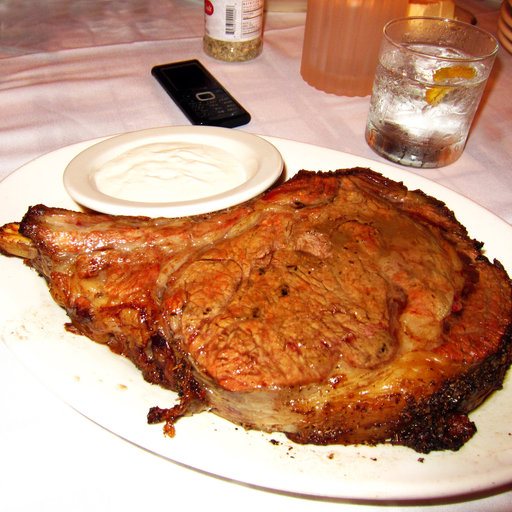

  Row 18114: label=steak, path=97656.jpg


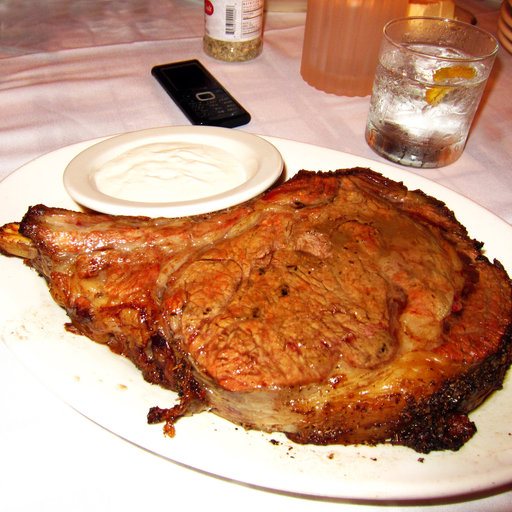


Duplicate group 2 — rows [2781, 2982]
  Row 2781: label=hamburger, path=3578279.jpg


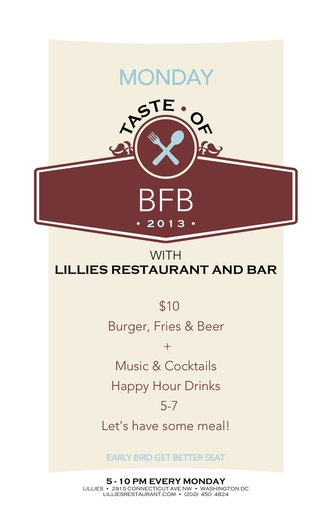

  Row 2982: label=hamburger, path=3783650.jpg


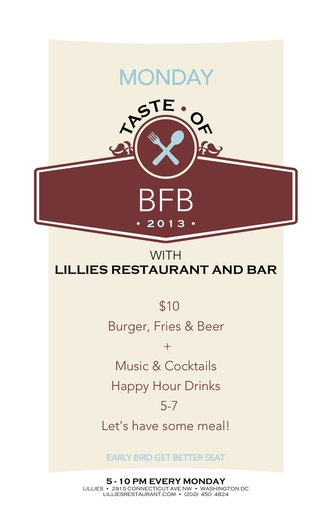


Duplicate group 3 — rows [22486, 59684]
  Row 22486: label=pancakes, path=2619752.jpg


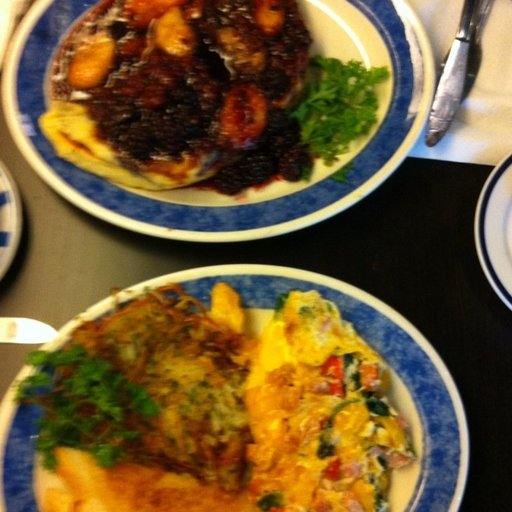

  Row 59684: label=omelette, path=2619753.jpg


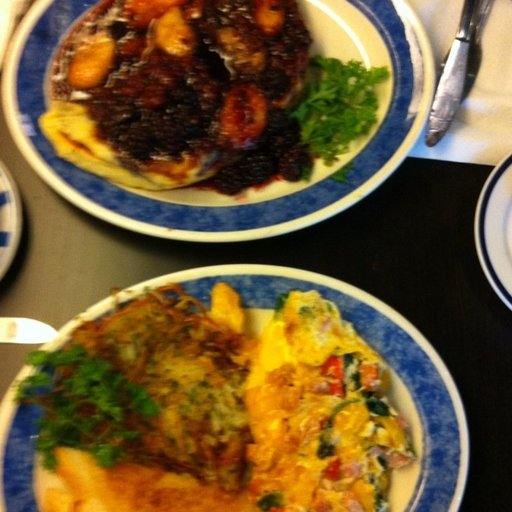


Duplicate group 4 — rows [35554, 35932]
  Row 35554: label=dumplings, path=180290.jpg


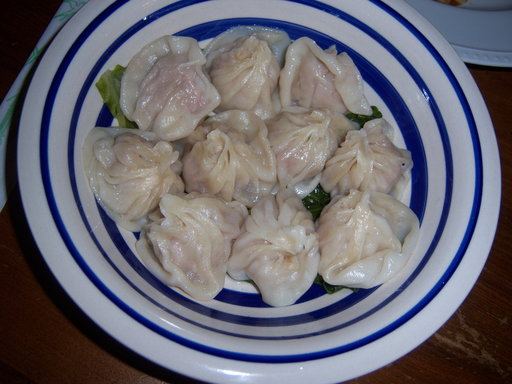

  Row 35932: label=dumplings, path=167000.jpg


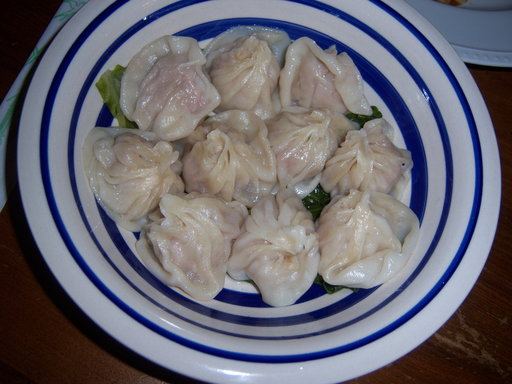


Duplicate group 5 — rows [50531, 50919]
  Row 50531: label=pho, path=51122.jpg


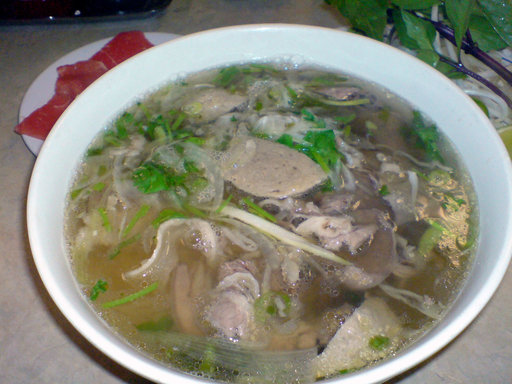

  Row 50919: label=pho, path=651427.jpg


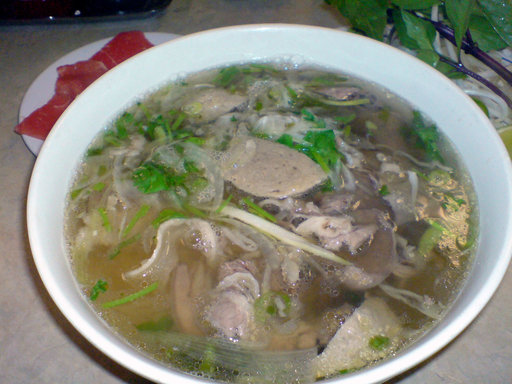


Duplicate group 6 — rows [50881, 50980]
  Row 50881: label=pho, path=4787.jpg


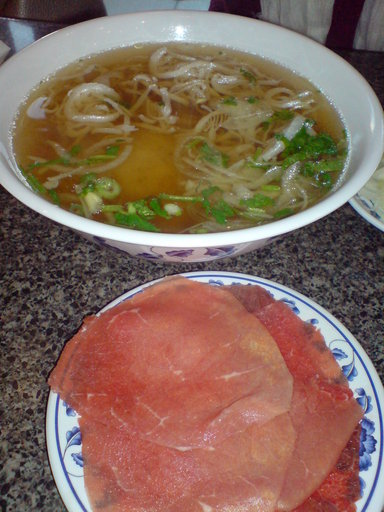

  Row 50980: label=pho, path=51112.jpg


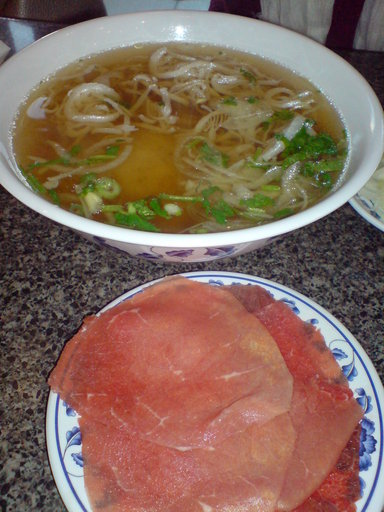


Duplicate group 7 — rows [71491, 99649]
  Row 71491: label=churros, path=2547960.jpg


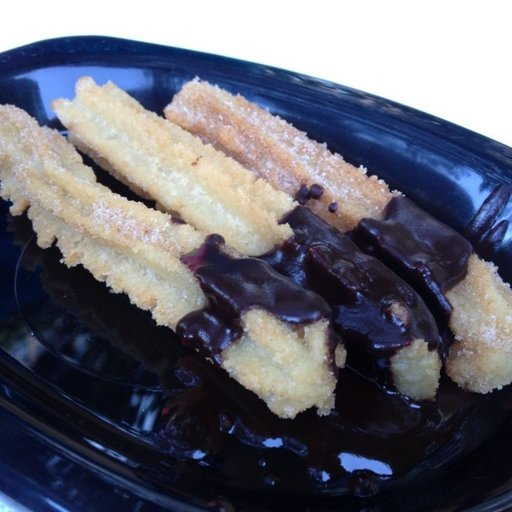

  Row 99649: label=churros, path=2617186.jpg


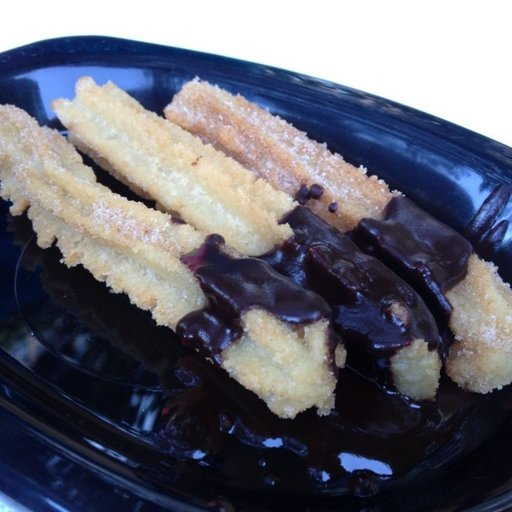


Duplicate group 8 — rows [74819, 100572]
  Row 74819: label=paella, path=2199941.jpg


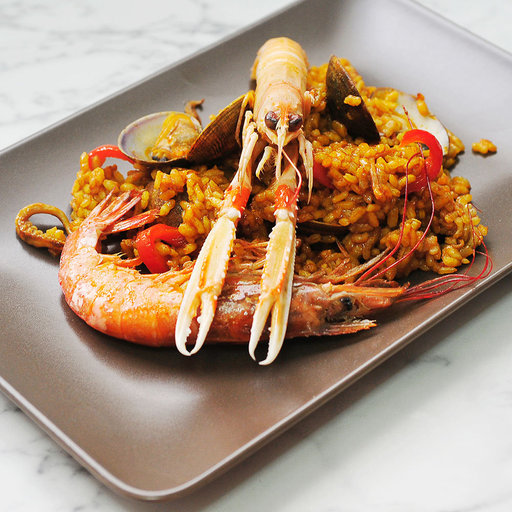

  Row 100572: label=paella, path=2199939.jpg


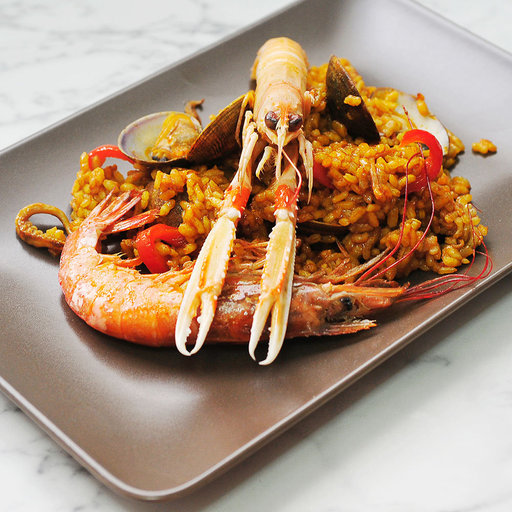

In [33]:
from collections import defaultdict
from io import BytesIO
from PIL import Image as PILImage
from IPython.display import display

groups = defaultdict(list)
for index, key in enumerate(keys):
    if key is not None:
        groups[key].append(index)

labels = arrow_table["label"].to_pylist()
duplicate_groups = [indices for indices in groups.values() if len(indices) > 1]

for group_num, indices in enumerate(duplicate_groups, start=1):
    print(f"\nDuplicate group {group_num} — rows {indices}")

    for index in indices:
        img = images[index]
        # print(f"  Row {index}: label={labels[index]!r}, path={img.get('path')}")
        print(f"  Row {index}: label={food_label_names[labels[index]]}, path={img.get('path')}")
        if img.get("bytes") is not None:
            display(PILImage.open(BytesIO(img["bytes"])))

#### Compute Limitations

For this project I am using a Nvidia 4060TI 8GB, 13th Gen Intel(R) Core(TM) i5-13600K, 3500 Mhz, 14 Core(s), 20 Logical Processor(s), and 32 GB DDR4 RAM

##### **Map each challenge to a concrete solution plan:**

   Examples:
   * **Imbalance →** `class_weight` or oversampling; report which one you’d try first and why.
   * **Length/size →** pick a target `max_text_length` (e.g., 95th percentile) with masking; for images, standardize resize/crop and basic augmentation.
   * **Noise/duplicates →** dedupe (hash/near-dup), drop empty/very short items, document any relabeling.
   * **Ambiguity →** consider merging labels (if justified), or add features (bigrams/char-ngrams; simple image augmentations).
   * **Overfitting risk →** early stopping on your primary metric, dropout/weight decay, freeze-then-finetune plan (for pretrained features).

In regards to size variance, I plan to resize/crop to 256 x 256 resolution.

Duplicates I identify using exact match of the image PIF. I will manually drop them by first examining the duplicates (8 total) and chose with justification
why I will drop the rows

For ambiguity I will not perfrom any class merging in preprocessing. First I will attempt to build models to classify all 101 classes. If certain classes
fail to generalize, I will revisit merging.

Overfitting risk I will avoid by using early stopping, dropout/weight decay, and freeze-then-finetuning if any pretrained image models are evaluated.

##### **Explore appropriate evaluation metrics:**

   Examples:
   * **Primary metric:** pick one aligned to your data (e.g., **macro-F1** if imbalanced; accuracy if balanced).
   * **Secondary metric(s):** per-class precision/recall, confusion matrix.
   * **Protocol:** stratified Train/Val/Test (e.g., 70/15/15), fixed seed, leakage checks.

I will use the accuracy metric since the classes are balanced in my dataset

I will evaluate the confusion matrix to understand which classes are common misclassified.

I will use a train/val/test split (70/15/15) with a fixed seed of 42.

### Graded Questions (3 pts each)

Write **a coherent response of approximately 75–125 words per question** in its designated Python answer variable. Be specific to your dataset and refer to relevant code, tables, plots, and numerical results where appropriate. Put supporting code in the programming cells rather than in your written answers. These word counts indicate the expected depth of explanation, not rigid limits. Straightforward factual questions (such as identifying inputs and outputs) may be answered more briefly when fully addressed.

A. **State the prediction task**  
   - Describe what your model will predict (the *label*).  
   - *Examples:*  
     - “Given a photo of food, predict which of 101 categories it belongs to.”  
     - “Given a news headline + summary, predict its topical category.”  

In [34]:
# Your answer here, NOT in the next cell

a2a = """
In the Food 101 dataset, the prediction task is multi-class classification. 

Given a photo of food, the task is to predict which of 101 food categories it belongs to.
"""

In [35]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a2a = {a2a}")

a2a = 
In the Food 101 dataset, the prediction task is multi-class classification. 

Given a photo of food, the task is to predict which of 101 food categories it belongs to.



B. **Define inputs and outputs**  
   - *Inputs:* what information the model receives (e.g., pixel data, tokenized text).  
   - *Outputs:* the categorical label the model will predict.  

In [36]:
food_all['image']

Column([<PIL.Image.Image image mode=RGB size=384x512 at 0x7F3326E45160>, <PIL.JpegImagePlugin.JpegImageFile image mode=RGB size=512x512 at 0x7F3327139C10>, <PIL.Image.Image image mode=RGB size=512x383 at 0x7F3327138BC0>, <PIL.Image.Image image mode=RGB size=512x348 at 0x7F3327138C50>, <PIL.Image.Image image mode=RGB size=512x512 at 0x7F3327139CD0>, ...])

In [37]:
# Your answer here, NOT in the next cell

a2b = """
Inputs: Pixel data in the PIL format. The data is RGB and has varying resolutions (minimum 242 x 512, maximum 512 x 512).

Outputs: The food category the model will predict, for example "steak" or "pancake".
"""

In [38]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a2b = {a2b}")

a2b = 
Inputs: Pixel data in the PIL format. The data is RGB and has varying resolutions (minimum 242 x 512, maximum 512 x 512).

Outputs: The food category the model will predict, for example "steak" or "pancake".



C. **Identify possible challenges**  
   - Imbalanced classes, noisy data, ambiguous labels, overlapping features, or missing data  
   - *Images:* variation in lighting, color, composition, or size.  
   - *Text:* class imbalance, duplicate stories, short or ambiguous headlines.  

In [39]:
# Your answer here, NOT in the next cell

a2c = """
The first possible challenge is with the image labeling. Some labels are ambiguous, where images can be classified with multiple labels interchangably. Other images are mislabeled,
for example an image of a menu could be labeled "hamburger".

Secondly, images contain variance in lighting, composition, and size. Depending on the restaurant the image was taken and possibly the camera, images have different lighting.
Images also have differing composition, including differences in backgrounds, silverware presence, and plate size and shape. Images also vary in size, from 242 x 512 up to 512 x 512.
"""

In [40]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a2c = {a2c}")

a2c = 
The first possible challenge is with the image labeling. Some labels are ambiguous, where images can be classified with multiple labels interchangably. Other images are mislabeled,
for example an image of a menu could be labeled "hamburger".

Secondly, images contain variance in lighting, composition, and size. Depending on the restaurant the image was taken and possibly the camera, images have different lighting.
Images also have differing composition, including differences in backgrounds, silverware presence, and plate size and shape. Images also vary in size, from 242 x 512 up to 512 x 512.



D. **Propose how you will prepare or improve the data to address the challenges**  
   - *Images:* resizing, normalization, data augmentation (flips, rotations, brightness, color jitter).  
   - *Text:* tokenization, stop-word removal, TF-IDF, class balancing, embeddings (choose an embedding approach and specify its vector size). 

In [41]:
# Your answer here, NOT in the next cell

a2d = """
Image resolution and size variance will be resolved by resizing images with padding to 256 x 256 resolution. This ensures images are in a normalized format without 
distorting images.

Variance in the lighting and composition will be addressed by using data augmentation techniques such as flips, rotations, brightness adjustments, and color jittering to produce 
additional image examples. These methods will ensure that a broad range of lighting and composition scenarios are learned across each of the categories.
"""

In [42]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a2d = {a2d}")

a2d = 
Image resolution and size variance will be resolved by resizing images with padding to 256 x 256 resolution. This ensures images are in a normalized format without 
distorting images.

Variance in the lighting and composition will be addressed by using data augmentation techniques such as flips, rotations, brightness adjustments, and color jittering to produce 
additional image examples. These methods will ensure that a broad range of lighting and composition scenarios are learned across each of the categories.



E. **Specify success metrics**  
   - Identify the metrics you plan to use to evaluate model performance—typically **accuracy** and/or **F1-score**, which are standard for classification tasks.  
   - Briefly explain **why** these metrics are appropriate for your dataset and goal. For instance, accuracy may suffice for well-balanced datasets, while F1-score better reflects performance when some classes are under-represented.
   - If your dataset is **imbalanced**, consider computing **per-class metrics** (e.g., precision, recall, or F1 for each label) or **macro-averaged** scores, which give equal weight to each class regardless of its size—ensuring that minority classes are evaluated fairly.
In some cases, weighted averages (which weight classes by their frequency) or **confusion matrices** can also provide useful insight.
> You haven't run any models yet, and we haven’t studied every possible metric, but you’re encouraged to ask your favorite generative AI tool which evaluation metrics might best fit your dataset!
   - Clearly state how you will interpret success—for example, “Our goal is to achieve at least 80% overall accuracy without large per-class disparities.”

In [43]:
# Your answer here, NOT in the next cell

a2e = """
The primary evaluation metric for this project is accuracy. Since this dataset can be framed as a multi-class classification problem and contains balanced classes, specialized metrics
beyond accuracy are not required to address class imbalance. The confusion matrix and classification report will be utilized to determine model performance across
each category in both broad statistics and exact counts of True Positives, False Positives, False Negatives, and True Negatives.

Our goal in this project is to achieve at least 80 percent overall accuracy without any categories having less than 50 percent accuracy.
"""

In [44]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a2e = {a2e}")

a2e = 
The primary evaluation metric for this project is accuracy. Since this dataset can be framed as a multi-class classification problem and contains balanced classes, specialized metrics
beyond accuracy are not required to address class imbalance. The confusion matrix and classification report will be utilized to determine model performance across
each category in both broad statistics and exact counts of True Positives, False Positives, False Negatives, and True Negatives.

Our goal in this project is to achieve at least 80 percent overall accuracy without any categories having less than 50 percent accuracy.



## Problem 3 — Data Preparation and Splits (30 pts)

### Goals

Implement the **data preparation and preprocessing steps** that you proposed in **Problems 1–2**. You’ll clean, normalize, and split your data so that it’s ready for modeling and reproducible modeling.

### Steps to Follow

1. **Load your chosen dataset**

   * Use `datasets.load_dataset()` from **Hugging Face** to load **Food-101** or **HuffPost**.
   * Display basic information (e.g., number of samples, feature names, example entries).

2. **Apply cleaning and normalization**

   * **Images:**

     * Ensure all images are in RGB format.
     * Resize or crop to a consistent shape (e.g., `224 × 224`).
     * Drop or fix any corrupted files.
   * **Text:**

     * Concatenate headline + summary (for HuffPost).
     * Strip whitespace, convert to lowercase if appropriate, and remove empty samples.
     * Optionally remove duplicates or extremely short entries.

3. **Standardize or tokenize the inputs**

   * **Images:**

     * Normalize pixel values (e.g., divide by 255.0).
     * Define a minimal augmentation pipeline (e.g., random flip, crop, or rotation).
   * **Text:**

     * Create a tokenizer or `TextVectorization` layer.
     * Set a target `max_length` based on your analysis from your earlier exploration in this notebook (e.g., 95th percentile).
     * Apply padding/truncation and build tensors for input + labels.

4. **Handle dataset-specific challenges**

   * If you identified **class imbalance**, compute label counts and, if needed, create a dictionary of `class_weights`.
   * If you noted **length or size variance**, verify that your truncation or resizing works as intended.
   * If you planned **noise filtering**, include the cleaning step and briefly explain your criteria (e.g., remove items with missing text or unreadable images).

5. **Create reproducible splits**

   * Split your cleaned dataset into **train**, **validation**, and **test** subsets (e.g., 80 / 10 / 10).
   * Use a fixed random seed for reproducibility (`random_seed = 42`).
   * Use **stratified splits**  (e.g., with `train_test_split` and `stratify = labels`).
   * Display the size of each subset.

6. **Document your pipeline**

   * Summarize your preprocessing steps clearly in Markdown or code comments.
   * Save or display a few representative examples after preprocessing to confirm the transformations are correct.




**Test-set policy:** Create and verify the test split, but **do not train on or evaluate models against it** in this milestone. Fit preprocessing parameters (e.g. vocabulary, scaling) on training data only; apply the fitted transformations to validation and test examples. Apply random augmentation to training data only.


In [45]:
food_all

Dataset({
    features: ['image', 'label'],
    num_rows: 101000
})

### Data Quality Validation

In [46]:
from PIL import Image as PILImage


def check_image(img):
  is_pil = isinstance(img, PILImage.Image)
  is_rgb = is_pil and img.mode == "RGB"
  return is_pil, is_rgb

In [47]:
results = []
for item in food_all:  # Replace 'train' with your split
  img = item["image"]  # Replace 'image' with your image column name
  is_pil, is_rgb = check_image(img)
  results.append((is_pil, is_rgb, getattr(img, "mode", None)))

/home/caleb/miniconda3/envs/tf_gpu/lib/python3.12/site-packages/PIL/TiffImagePlugin.py:950: UserWarning: Truncated File Read
  warnings.warn(str(msg))


In [48]:
# Verify if all are PIL and RGB
all_pil_and_rgb = all(r[0] and r[1] for r in results)
print("All are PIL and RGB:", all_pil_and_rgb)

All are PIL and RGB: False


In [49]:
all(r[0] for r in results)

True

In [50]:
all(r[1] for r in results)

False

In [51]:
Counter(r[1] for r in results)

Counter({True: 100997, False: 3})

In [52]:
non_rgb_indexes = [
    i for i, item in enumerate(food_all) if item["image"].mode != "RGB"
]

print("Non-RGB indexes:", non_rgb_indexes)

/home/caleb/miniconda3/envs/tf_gpu/lib/python3.12/site-packages/PIL/TiffImagePlugin.py:950: UserWarning: Truncated File Read
  warnings.warn(str(msg))


Non-RGB indexes: [18508, 23754, 56094]


  Row 18508: label=steak, path=1340977.jpg


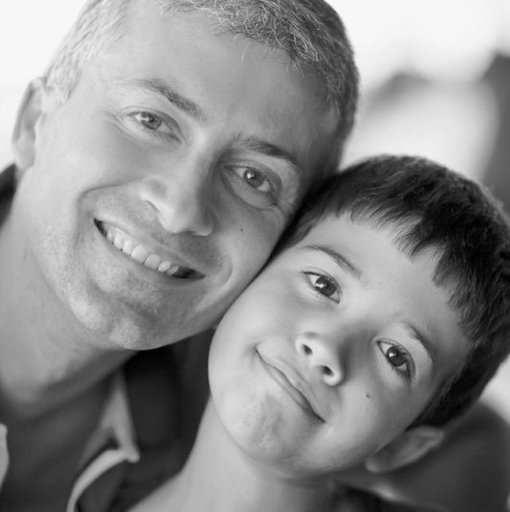

  Row 23754: label=lasagna, path=3787908.jpg


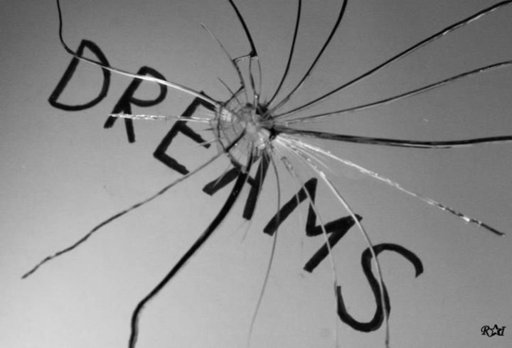

  Row 56094: label=bread_pudding, path=1375816.jpg


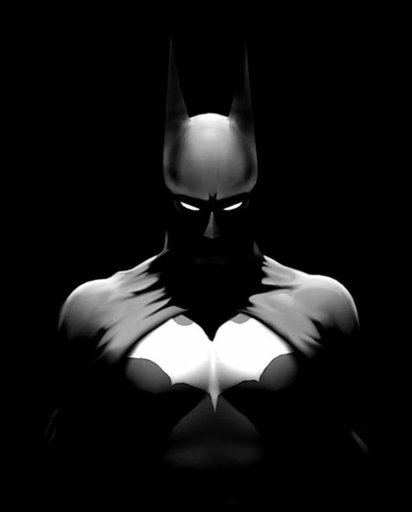

In [ ]:
for index in non_rgb_indexes:
    img = images[index]
    print(f"  Row {index}: label={food_label_names[labels[index]]}, path={img.get('path')}")
    if img.get("bytes") is not None:
        display(PILImage.open(BytesIO(img["bytes"])))

None of these B/W images are food so we will drop them

### Remove Invalid Data

In [ ]:
non_rgb_indexes

[18508, 23754, 56094]

In [ ]:
indices_to_remove

{2781, 2982, 18114, 22486, 35932, 50919, 50980, 99649, 100572}

In [ ]:
indices_to_remove = indices_to_remove | set(non_rgb_indexes)
indices_to_remove

{2781,
 2982,
 18114,
 18508,
 22486,
 23754,
 35932,
 50919,
 50980,
 56094,
 99649,
 100572}

In [ ]:
keep_indices = [
    i for i in range(len(food_all))
    if i not in indices_to_remove
]
food_all_clean = food_all.select(keep_indices)

print(f"Removed {len(food_all) - len(food_all_clean)} rows")

Removed 12 rows


### Preprocessing Pipeline

In [ ]:
from datasets import DatasetDict

label_col = "label"

# Hold out 10% for testing.
temp_split = food_all_clean.train_test_split(
    test_size=0.10,
    seed=42,
    stratify_by_column=label_col,
)

# Split 1/9 of the remaining 90% for validation (10% of the full dataset).
train_val_split = temp_split["train"].train_test_split(
    test_size=1 / 9,
    seed=42,
    stratify_by_column=label_col,
)

food_splits = DatasetDict({
    "train": train_val_split["train"],
    "validation": train_val_split["test"],
    "test": temp_split["test"],
})

for name, split in food_splits.items():
    print(f"{name}: {len(split):,} images")

train: 80,790 images
validation: 10,099 images
test: 10,099 images


In [ ]:
import numpy as np
import tensorflow as tf
from PIL import Image, ImageOps
from datasets import Array3D, Features
from tensorflow.keras import layers

AUTOTUNE = tf.data.AUTOTUNE
BATCH_SIZE = 32
# 128 x 128 (3x less pixels than 224x224 so faster epochs)
IMAGE_SIZE = (128, 128)

# Parallelize workers used by to_tf_dataset to load batches
NUM_WORKERS = 4

# Hugging Face .map() passes one example dictionary at a time.
# Keep this step deterministic; random augmentation belongs in the
# TensorFlow training pipeline so it can vary across epochs.
def preprocess_example(example):
    # 1. Ensure each row is already in RGB (We already have checked this at this point but it is a safe cast)
    image = example["image"].convert("RGB")

    # 2. Resize and Crop
    image = ImageOps.fit(image, IMAGE_SIZE, method=Image.Resampling.BILINEAR)

    return {
        "image": np.asarray(image, dtype=np.uint8),
        "label": int(example["label"]),
    }

# Tell Hugging Face the fixed shape and type of the processed images.
processed_features = Features({
    "image": Array3D(shape=(128, 128, 3), dtype="uint8"),
    "label": food_splits["train"].features["label"],
})

# Apply the deterministic preprocessing to each existing split.
# The split names remain "train", "validation", and "test".
processed_splits = food_splits.map(
    preprocess_example,
    remove_columns=food_splits["train"].column_names,
    features=processed_features,
)


def make_tf_dataset(split, *, training=False):
    # Keep images uint8 (0-255 all the way through the tf.data pipeline. Float32 is 4x larger)
    return split.to_tf_dataset(
        columns=['image'],
        label_cols=['label'],
        batch_size=BATCH_SIZE,
        shuffle=training,
        num_workers=NUM_WORKERS,
        prefetch=True
    )

train_ds = make_tf_dataset(processed_splits["train"], training=True)
val_ds = make_tf_dataset(processed_splits["validation"])
test_ds = make_tf_dataset(processed_splits["test"])

Map:   0%|          | 0/80790 [00:00<?, ? examples/s]

Map:   0%|          | 0/10099 [00:00<?, ? examples/s]

Map:   0%|          | 0/10099 [00:00<?, ? examples/s]

/home/caleb/miniconda3/envs/tf_gpu/lib/python3.12/site-packages/datasets/arrow_dataset.py:410: FutureWarning: The output of `to_tf_dataset` will change when a passing single element list for `labels` or `columns` in the next datasets version. To return a tuple structure rather than dict, pass a single string.
Old behaviour: columns=['a'], labels=['labels'] -> (tf.Tensor, tf.Tensor)  
             : columns='a', labels='labels' -> (tf.Tensor, tf.Tensor)  
New behaviour: columns=['a'],labels=['labels'] -> ({'a': tf.Tensor}, {'labels': tf.Tensor})  
             : columns='a', labels='labels' -> (tf.Tensor, tf.Tensor) 
  warnings.warn(
I0000 00:00:1794680190.941728    4356 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 5527 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 4060 Ti, pci bus id: 0000:01:00.0, compute capability: 8.9


In [ ]:
preprocessing_layers = tf.keras.Sequential([
    layers.Rescaling(1.0 / 255), # uint8 [0,255] to float32 [0,1]
    layers.RandomFlip("horizontal"),
    layers.RandomBrightness(0.1, value_range=(0.0, 1.0)),
    layers.RandomContrast(0.1),
], name='preprocessing_layers')

In [ ]:
# import numpy as np
# import tensorflow as tf
# from PIL import Image, ImageOps
# from datasets import Array3D, Features

# AUTOTUNE = tf.data.AUTOTUNE
# BATCH_SIZE = 32
# IMAGE_SIZE = (128, 128)  # PIL uses (width, height); these are square.


# # Hugging Face .map() passes one example dictionary at a time.
# # Keep this step deterministic; random augmentation belongs in the
# # TensorFlow training pipeline so it can vary across epochs.
# def preprocess_example(example):
#     # 1. Ensure each row is already in RGB (We already have checked this at this point but it is a safe cast)
#     image = example["image"].convert("RGB")

#     # 2. Resize and Crop
#     image = image.resize(IMAGE_SIZE, resample=Image.Resampling.BILINEAR)
#     # image = ImageOps.pad(
#     #     image,
#     #     IMAGE_SIZE,
#     #     method=Image.Resampling.BILINEAR,
#     #     color=(0, 0, 0),
#     # )

#     return {
#         "image": np.asarray(image, dtype=np.uint8),
#         "label": int(example["label"]),
#     }


# # Tell Hugging Face the fixed shape and type of the processed images.
# processed_features = Features({
#     "image": Array3D(shape=(128, 128, 3), dtype="uint8"),
#     "label": food_splits["train"].features["label"],
# })

# # Apply the deterministic preprocessing to each existing split.
# # The split names remain "train", "validation", and "test".
# processed_splits = food_splits.map(
#     preprocess_example,
#     remove_columns=food_splits["train"].column_names,
#     features=processed_features,
# )


# def make_tf_dataset(split, *, training=False):
#     dataset = split.to_tf_dataset(
#         columns=["image"],
#         label_cols=["label"],
#         batch_size=BATCH_SIZE,
#         shuffle=training,
#     )
    

#     def prepare_batch(images, labels):
#         images = tf.cast(images, tf.float32) / 255.0

#         if training:
#             images = tf.image.random_flip_left_right(images)
#             images = tf.image.random_brightness(images, max_delta=0.1)
#             images = tf.image.random_contrast(
#                 images,
#                 lower=0.9,
#                 upper=1.1,
#             )
#             images = tf.clip_by_value(images, 0.0, 1.0)

#         return images, tf.cast(labels, tf.int32)

#     return (
#         dataset
#         .map(prepare_batch, num_parallel_calls=AUTOTUNE)
#         .prefetch(AUTOTUNE)
#     )


# train_ds = make_tf_dataset(processed_splits["train"], training=True)
# val_ds = make_tf_dataset(processed_splits["validation"])
# test_ds = make_tf_dataset(processed_splits["test"])

### Test Pipeline

I0000 00:00:1794680205.082458    4356 generator_dataset_op.cc:213] Memory patch applied: M_TRIM_THRESHOLD=128 kb was set.
I0000 00:00:1794680206.270851   13973 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794680206.441926   13976 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794680206.903234   13978 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794680207.290617   139

Batch shape: (32, 128, 128, 3)
Image dtype: <dtype: 'int64'>
Pixel range: 0.0 to 255.0
Labels: [10 95 13 95 51 83  9 52]


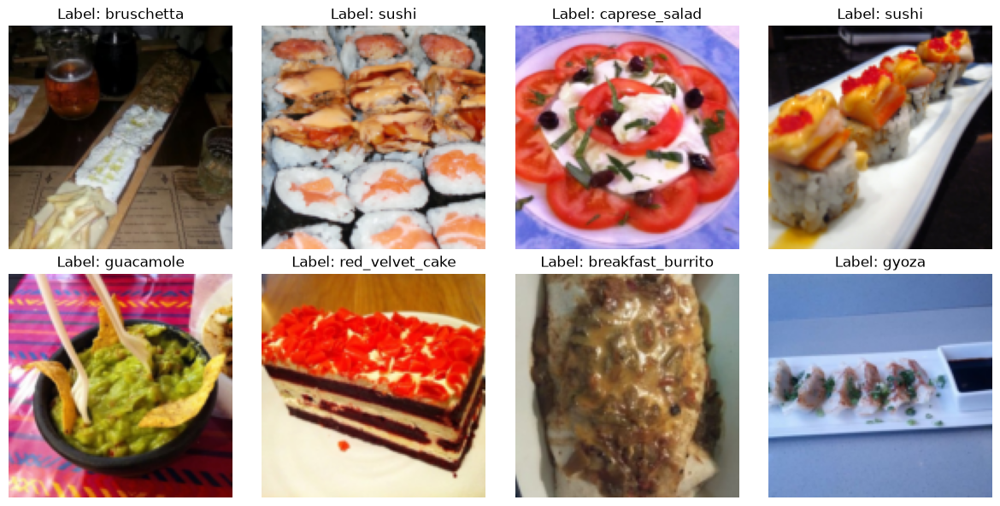

In [ ]:
import matplotlib.pyplot as plt

images, labels = next(iter(train_ds.take(1)))

print("Batch shape:", images.shape)
print("Image dtype:", images.dtype)
print("Pixel range:", float(tf.reduce_min(images)), "to", float(tf.reduce_max(images)))
print("Labels:", labels[:8].numpy())

fig, axes = plt.subplots(2, 4, figsize=(12, 6))

for ax, image, label in zip(axes.flat, images[:8], labels[:8]):
    ax.imshow(image.numpy())
    ax.set_title(f"Label: {food_label_names[label]}")
    ax.axis("off")

plt.tight_layout()
plt.show()

### Grading for Problem 3 (30 pts)

- **Implementation (18 pts):** correct data loading and cleaning; appropriate preprocessing; reproducible, separate train/validation/test splits with leakage prevention; and checks/outputs demonstrating that the prepared data are suitable for modeling.
- **Written answers (12 pts):** Questions A–D, **3 pts each**. Explain the actual implementation and cite your notebook results.

### Graded Questions (3 pts each)

Write **a coherent response of approximately 100–150 words per question** in its designated Python answer variable. Be specific to your dataset and refer to relevant code, tables, plots, and numerical results where appropriate. Put supporting code in the programming cells rather than in your written answers. These word counts indicate the expected depth of explanation, not rigid limits.

A. **Data Loading and Cleaning:**
   Describe how you loaded your dataset and the key cleaning steps you implemented (e.g., handling missing data, normalizing formats, or removing duplicates).



In [ ]:
# Your answer here, NOT in the next cell

a3a = """
I loaded the ethz/food101 (train+test+validation) dataset using the Huggingface datasets library.

In the cleaning steps I first validated that there are 0 missing values across the image and label columns in the dataset. 

Next, I identified 8 duplicate values and removed them. 5 of the duplicates had the same label across both images of which I randomly removed one. 
3 of the images had differing labels, so I manually removed the image with the wrong label. Additionally, 1 set of duplicates were both 
pictures of a menu rather than a food item, so I deleted both. Overall, I identified the following indices to remove from the dataset:
{2781, 2982, 18114, 22486, 35932, 50919, 50980, 99649, 100572}. This cleaning step showed that images can have the wrong label, or be invalid
by not being an image of a food item.

The next cleaning step was normalization of image format. I ensured that all images were RGB format. I encountered 3 images which were in Black and White. Each
image was not a food item, so I removed them from the dataset.
"""

In [ ]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a3a = {a3a}")

a3a = 
I loaded the ethz/food101 (train+test+validation) dataset using the Huggingface datasets library.

In the cleaning steps I first validated that there are 0 missing values across the image and label columns in the dataset. 

Next, I identified 8 duplicate values and removed them. 5 of the duplicates had the same label across both images of which I randomly removed one. 
3 of the images had differing labels, so I manually removed the image with the wrong label. Additionally, 1 set of duplicates were both 
pictures of a menu rather than a food item, so I deleted both. Overall, I identified the following indices to remove from the dataset:
{2781, 2982, 18114, 22486, 35932, 50919, 50980, 99649, 100572}. This cleaning step showed that images can have the wrong label, or be invalid
by not being an image of a food item.

The next cleaning step was normalization of image format. I ensured that all images were RGB format. I encountered 3 images which were in Black and White. Each
image wa

B. **Preprocessing and Standardization:**
   Summarize your preprocessing pipeline. Include any normalization, tokenization, resizing, or augmentation steps, and explain why each was necessary for your dataset.
  

In [ ]:
# Your answer here, NOT in the next cell

a3b = """
In the preprocessing pipeline I introduced image resizing and data augmentation.

First, in the image resizing step I chose a common resolution of 128x128. I used resizing with padding using the ImageOps library,
allowing the resizing to be offloaded to CPU while GPU is used for the model training, effectively parallelizing the workload. I opted to
use 128x128 rather than a higher resolution due to computational complexity. Workloads of 224x224 I tested took over an hour to train on a single
4060ti GPU for baseline models, limiting the options for experimenting with more complex model models.

Additionally, I introduced data augmentations including random flip (left to right), contrast, and brightness. These augmentations are included in the Tensorflow pipeline, 
allowing new augmentations to be generated each training epoch. This preprocessing step provides additional synthetic examples which could be encountered by the model in production.
Since we know brightness, contrast, and composition vary for each image, these augmentations should improve generalization.
"""

In [ ]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a3b = {a3b}")

a3b = 
In the preprocessing pipeline I introduced image resizing and data augmentation.

First, in the image resizing step I chose a common resolution of 224x224. I used resizing without padding since it is natively supported by HuggingFace datasets,
allowing the resizing to be offloaded to CPU while GPU is used for the model training, effectively parallelizing the workload.

Additionally, I introduced data augmentations including random flip (left to right), contrast, and brightness. These augmentations are included in the Tensorflow pipeline, 
allowing new augmentations to be generated each training epoch. This preprocessing step provides additional synthetic examples which could be encountered by the model in production.
Since we know brightness, contrast, and composition vary for each image, these augmentations should improve generalization.



C. **Train/Validation/Test Splits:**
   Explain how you divided your data into subsets, including the split ratios, random seed, and any stratification or leakage checks you used to verify correctness.


In [ ]:
# Your answer here, NOT in the next cell

a3c = """
I divided the dataset of 101,000 images into train/test/validation sets. I used an 80/10/10 split using the random seed of 42. I stratify each split by using the target variable, to ensure
equal class distribution across the datasets. Due to the large dataset size, I opted to use the 80/10/10 split since 10 percent of the dataset should still be large enough
for validation and testing, while allowing the maximum number of instances for training.
"""

In [ ]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a3c = {a3c}")

a3c = 
I divided the dataset of 101,000 images into train/test/validation sets. I used an 80/10/10 split using the random seed of 42. I stratify each split by using the target variable, to ensure
equal class distribution across the datasets. Due to the large dataset size, I opted to use the 80/10/10 split since 10 percent of the dataset should still be large enough
for validation and testing, while allowing the maximum number of instances for training.



D. **Class Distribution and Balance:**
   Report your label counts and describe any class imbalances you observed. If applicable, explain how you addressed them (e.g., weighting, oversampling, or data augmentation).


In [ ]:
food_all_clean

Dataset({
    features: ['image', 'label'],
    num_rows: 100988
})

In [ ]:
# Your answer here, NOT in the next cell

a3d = """
The Food 101 dataset does not contain any class imbalance. It contains 101 unique classes of foods and 101,000 instances total, with 1,000 instances per class.
After cleaning, the dataset contains 100,988 instances. All classes contain 1,000 instances except for the following labels and corresponding counts:
72      999
59      999
32      999
8       999
23      999
71      999
53      998
93      998
75      998

Since the greatest difference in class size is 2 instances, I did not use any adjusted weighting or oversampling to accomodate the dataset. 
"""

In [ ]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a3d = {a3d}")

a3d = 
The Food 101 dataset does not contain any class imbalance. It contains 101 unique classes of foods and 101,000 instances total, with 1,000 instances per class.
After cleaning, the dataset contains 100,988 instances. All classes contain 1,000 instances except for the following labels and corresponding counts:
72      999
59      999
32      999
8       999
23      999
71      999
53      998
93      998
75      998

Since the greatest difference in class size is 2 instances, I did not use any adjusted weighting or oversampling to accomodate the dataset. 



## Problem 4 — Baseline Model (30 pts)

### Goal

Build and train a **simple, fully functional baseline model** to establish a reference level of performance for your dataset.
This baseline will help you evaluate whether later architectures and fine-tuning steps actually improve results.


### Steps to Follow

1. **Construct a baseline model**

   * **Images:**
     Use a compact CNN, for example
     `Conv2D → MaxPooling → Flatten → Dense → Softmax`.
   * **Text:**
     Use a small embedding-based classifier such as
     `Embedding → GlobalAveragePooling → Dense → Softmax`.
   * Keep the model small enough to train in minutes on Colab.

2. **Compile the model**

   * Optimizer: `Adam` or `AdamW`.
   * Loss: Use `categorical_crossentropy` for one-hot-encoded labels or `sparse_categorical_crossentropy` for integer class labels.
   * Metrics: at least `accuracy`; add `F1` if appropriate.

3. **Train and validate**

   * Use **early stopping** on validation loss with a patience of approximately 5 epochs.
   * Record number of epochs trained and total runtime.

4. **Visualize results**

   * Plot **training vs. validation accuracy and loss**.
   * Carefully observe: does the model underfit, overfit, or generalize reasonably?

5. **Report baseline performance**

   * The most important metric is the **validation accuracy at the epoch of minimum validation loss**; this serves as your **benchmark** for all later experiments in the final project.
   * **Do not evaluate on the test set yet.** Report validation performance only. Preserve the test split for final evaluation.

### Baseline Model

In [ ]:
import keras
from keras import layers


he = initializers.HeNormal()
num_classes = 101

model = keras.Sequential([
    layers.Input(shape=(*IMAGE_SIZE, 3)), # 128x128 with 3 channels (RGB)
    preprocessing_layers,  # rescale + augment during training
    layers.Conv2D(32, (3,3), activation="relu", kernel_initializer=he, padding="same"),
    layers.MaxPooling2D(),
    layers.GlobalAveragePooling2D(),  # (112, 112, 64) -> (64,)

    # Compact head
    layers.Dense(128, activation='relu', kernel_initializer=he),
    layers.Dense(num_classes, activation='softmax')
])

In [ ]:
def plot_learning_curves(hist, title, verbose=True):
    
    val_losses = hist.history['val_loss']
    min_val_loss = min(val_losses)
    min_val_epoch = val_losses.index(min_val_loss)
    val_acc_at_min_loss = hist.history['val_accuracy'][min_val_epoch]

    epochs = range(1, len(val_losses) + 1)  # epoch numbers starting at 1

    fig, axs = plt.subplots(2, 1, figsize=(8, 8), sharex=True)

    # --- Loss Plot ---
    axs[0].plot(epochs, hist.history['loss'], label='train loss')
    axs[0].plot(epochs, hist.history['val_loss'], label='val loss')
    axs[0].scatter(min_val_epoch + 1, min_val_loss, color='red', marker='x', s=50, label='min val loss')
    axs[0].set_title(f'{title} - Categorical Cross-Entropy Loss')
    axs[0].set_ylabel('Loss')
    axs[0].legend()
    axs[0].grid(True)

    # --- Accuracy Plot ---
    axs[1].plot(epochs, hist.history['accuracy'], label='train acc')
    axs[1].plot(epochs, hist.history['val_accuracy'], label='val acc')
    axs[1].scatter(min_val_epoch + 1, val_acc_at_min_loss, color='red', marker='x', s=50, label='acc @ min val loss')
    axs[1].set_title(f'{title} - Accuracy')
    axs[1].set_xlabel('Epoch')
    axs[1].set_ylabel('Accuracy')
    axs[1].legend()
    axs[1].grid(True)
    axs[1].set_ylim(0, 1.05)

    plt.tight_layout()
    plt.show()

    if verbose:
        print(f"Final Training Loss:            {hist.history['loss'][-1]:.4f}")
        print(f"Final Training Accuracy:        {hist.history['accuracy'][-1]:.4f}")
        print(f"Final Validation Loss:          {hist.history['val_loss'][-1]:.4f}")
        print(f"Final Validation Accuracy:      {hist.history['val_accuracy'][-1]:.4f}")
        print(f"Minimum Validation Loss:        {min_val_loss:.4f} (Epoch {min_val_epoch + 1})")
        print(f"Validation Accuracy @ Min Loss: {val_acc_at_min_loss:.4f}")

    results[title] = (val_acc_at_min_loss,min_val_epoch + 1)

results = {}

def print_results():
    for title, (acc, ep) in sorted(results.items(), 
                                   key=lambda kv: kv[1][0],   # kv[1] is (acc, epoch); [0] is acc
                                   reverse=True
                                  ):
        print(f"{title:<40}\t{acc:.4f}\t{ep}")

In [ ]:
# Uses globals: train_ds, val_ds, test_ds

def train_and_test(model, 
                   epochs        = 500,
                   lr_schedule   = 1e-3,
                   optimizer     = "Adam",
                   title         = "Learning Curves",
                   use_early_stopping = True,
                   patience      = 5,
                   min_delta     = 0.0001,
                   callbacks     = [],
                   verbose       = 0,
                   return_history = False,
                   evaluate_test_set = False
                  ):

    print(f"\n{title}\n")

    # Choose optimizer
    if optimizer == "Adam":
        opt = Adam(learning_rate=lr_schedule)
    else:
        opt = optimizer

    # Compile
    model.compile(
        optimizer=opt,
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    early_stop = EarlyStopping(
        monitor='val_loss',
        patience=patience,
        min_delta=min_delta,
        restore_best_weights=True,
        verbose=verbose
    )

    cbs = ([early_stop] if use_early_stopping else []) + callbacks

    start = time.time()

    # Fit on tf.data datasets (already batched)
    history = model.fit(
        train_ds,
        epochs=epochs,
        validation_data=val_ds,
        callbacks=cbs,
        verbose=verbose
    )

    # Determine best validation accuracy
    if use_early_stopping and hasattr(early_stop, "best_epoch") and early_stop.best_epoch is not None:
        best_epoch = early_stop.best_epoch
        best_acc   = history.history['val_accuracy'][best_epoch]
    else:
        best_epoch = int(np.argmax(history.history['val_accuracy']))
        best_acc   = history.history['val_accuracy'][best_epoch]

    plot_learning_curves(history, title=title)

    # Evaluate on tf.data test set
    if evaluate_test_set:
        test_loss, test_accuracy = model.evaluate(test_ds, verbose=0)

        print(f"\nTest Loss: {test_loss:.4f}")
        print(f"Test Accuracy: {test_accuracy:.4f}")
        print(f"\nValidation-Test Gap (accuracy): {abs(best_acc - test_accuracy):.6f}")

    end = time.time()
    print(f"\nExecution Time: " + format_hms(end-start))

    if return_history:
        return history


In [ ]:
baseline_history = train_and_test(model, title="Baseline Model", verbose=0, return_history=True)


Baseline



/home/caleb/miniconda3/envs/tf_gpu/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
I0000 00:00:1794682907.845184   36206 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794682908.278732   36208 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
/home/caleb/miniconda3/envs/tf_gpu/lib/python3.12/site-packages/requests/__init__.py:92

In [ ]:
plot_learning_curves(baseline_history, "Baseline Learning Curves")

NameError: name 'baseline_history' is not defined

In [ ]:
print_results()

### Grading for Problem 4 (30 pts)

- **Implementation (18 pts):** a functional, appropriate baseline model; correct compilation and training; appropriate use of training and validation sets (no test evaluation); learning curves; and reproducible, clearly reported validation results.
- **Written answers (12 pts):** Questions A–D, **3 pts each**. Explain the actual model, training behavior, and results.

### Graded Questions (3 pts each)

Write **a coherent response of approximately 100–150 words per question** in its designated Python answer variable. Be specific to your dataset and refer to relevant code, tables, plots, and numerical results where appropriate. Put supporting code in the programming cells rather than in your written answers. These word counts indicate the expected depth of explanation, not rigid limits.

A. **Model Architecture:**
   Describe your baseline model and justify why this structure suits your dataset.

In [ ]:
# Your answer here, NOT in the next cell

a4a = """
For the modeling approach we have the goal of classifying images given a 128x128 RGB image into 101 unique classes. To
support this requirement in the baseline model, I first selected a 128x128x3 Input layer (128x128 image dimension with 3 channels for RGB). I also selected
a Dense Softmax output layer with 101 units to perform the final multi-class classification.

The main components of the baseline model I selected are a 32 filter Convolutional 2D layer with 3x3 kernels and 1 stride and ReLu activation function, MaxPooling2D, GlobalAveragePooling2D,
and a Dense 128 layer with ReLu activation and HeNormal initializer. I selected the Convolutional layer to learn the visual features like colors and shapes, and chose
a 32 filter size since it minimizes computational complexity for the baseline. Next, MaxPooling2D and GlobalAveragePooling2D are used to reduce the dimensions of the image
and summarize the feature map.

These choices resulted in the following architecture for the baseline model:
- 128x128x3 Input layer (128x128 image dimension with 3 channels for RGB)
- 32 filter size Convulutional 2D layer with 3,3 stride and ReLu activation function
- MaxPooling2D
- GlobalAveragePooling2D
- Dense 128 layer with ReLu activation function and HeNormal initializer, 
- Dense Softmax output layer for classification with 101 units for each possible label

In future models, I will experiment with other approaches such as larger and extra convolutional and dense layers, and also transfer learning with frozen and unfrozen heads. 
"""

In [ ]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a4a = {a4a}")

a4a = 
Write your answer here.



B. **Training Behavior:**
   Summarize the model’s training and validation curves. What trends did you observe?

In [ ]:
# Your answer here, NOT in the next cell

a4b = """
Write your answer here.
"""

In [ ]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a4b = {a4b}")

a4b = 
Write your answer here.



 C. **Baseline Metrics:**
   Report validation metrics only. What does this performance tell you about dataset difficulty?

In [ ]:
# Your answer here, NOT in the next cell

a4c = """
The validation accuracy accuracy for the baseline model is X at the minimum validation loss of Y.

This result shows that the Food 101 dataset is difficult for a relatively simple CNN architecture to learn. I hypothesize that the large number of unique classes to identify in
combination with the simple architecture of the baseline model leads to these results. Additionally, we learned in EDA that there are many ambiguous classes which could lead
to confusion in classification of these classes. 
"""

In [ ]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a4c = {a4c}")

a4c = 
Write your answer here.



  D. **Reflection:**
   What are the main limitations of your baseline? Which specific improvements (depth, regularization, pretraining) would you try next?
  

In [ ]:
# Your answer here, NOT in the next cell

a4d = """
The primary limitations of the baseline model are the complexity and number of the convolutional and dense layers, which are a 32 filter convolutional layer
and 64 unit dense layer respectively. In future models, I will experiment with increased depth such as 64 and 128 and additionally stack layers such as the following 
configuration: Conv2D 32, Conv2D 64, Dense 64, Dense 128. By increasing model complexity generalization may improve. Additionally, I will experiment with different 
hyperparameters such as learning rate and regularization to see whether constraining the model or adapting its learning schedule improves convergence. Finally, I 
will evaluate performance of pre-trained models such as ResNet or MobileNet. For pretrained models, I will evaluate performance when only training the classification head
and then unfreezing the backbone for further fine tuning. This will help to determine whether the baseline model's limitation 
is the underlying features it learned like color and shapes. To evaluate each of these specific improvements, I will use validation accuracy and learning curves.
"""

In [ ]:
# Graded Answer
# DO NOT change this cell in any way
# Be SURE to run this cell before submitting

print(f"a4d = {a4d}")

a4d = 
Write your answer here.



## Final checks and AI-use disclosure (read but not graded)

**AI question:** Describe what use you made of generative AI tools in preparing this milestone, consistent with CDS policy. Include what you used the tools for and how you verified the results.

**Your answer here:**

### Submission checklist

- [ ] I explored both datasets, chose one, and removed the unused dataset’s starter section.
- [ ] The submitted notebook has my name and answers to Problems 1–4.
- [ ] The notebook contains the code, relevant outputs, plots, and training/validation metrics for the baseline.
- [ ] The test set was created but **not used to make modeling decisions or report baseline test performance**.
- [ ] I restarted the kernel and ran the notebook from top to bottom, without errors.
- [ ] I documented random seeds, dataset sampling, dependencies, and AI-tool use.


## Appendix: A quick guide to Hugging Face Datasets

#### 1) What are they?

* A **table-like** dataset: rows = examples, columns = named fields (e.g., `"image"`, `"label"`, `"headline"`).
* Backed by **Apache Arrow** → fast, memory-efficient, lazy transforms.
* Two core objects:

  * `Dataset` — one table of rows/columns.
  * `DatasetDict` — a dict of splits, e.g. `{"train": Dataset, "val": Dataset, "test": Dataset}`.


#### 2) Load and inspect

```python
from datasets import load_dataset

# Food-101 (images)
food = load_dataset("food101", split="train+validation")  # both splits at once
len(food), food.column_names, food.features
# -> (≈101000, ['image','label'], {'label': ClassLabel(num_classes=101, names=[...])})

# Access by name (not by numeric column index!)
row0 = food[0]
img0, y0 = row0["image"], row0["label"]     # PIL image, int id
label_names = food.features["label"].names
label_names[y0]
```

For text (HuffPost JSON mirror):

```python
url = "https://huggingface.co/datasets/khalidalt/HuffPost/resolve/main/News_Category_Dataset_v2.json"
huff = load_dataset("json", data_files=url, split="train")
huff.column_names  # e.g. ['headline','short_description','category','authors','link','date']
```


#### 3) Common transforms

`Dataset`s are **immutable**: ops return a new dataset.

* **Map** (add/modify columns):

```python
def mk_text(ex):
    h = (ex.get("headline") or "").strip()
    s = (ex.get("short_description") or "").strip()
    return {"text": (h + " [SEP] " + s).strip()}

huff = huff.map(mk_text)  # adds 'text' column
```

* **Class-encode** labels (strings → integers with a vocabulary):

```python
from datasets.features import ClassLabel
if not isinstance(huff.features["category"], ClassLabel):
    huff = huff.class_encode_column("category")  # now ints with .names
```

* **Filter / select / rename / drop**:

```python
small = huff.select(range(5000))  # first 5k rows
huff = huff.remove_columns(["authors","link","date"])
huff = huff.rename_column("category", "label")
```


#### 4) Splitting & shuffling

```python
# Stratified 80/10/10 on Food-101 by 'label'
from datasets import DatasetDict
label_col = "label"

tmp = food.train_test_split(test_size=0.10, seed=42, stratify_by_column=label_col)
train_val = tmp["train"].train_test_split(test_size=1/9, seed=42, stratify_by_column=label_col)
ds = DatasetDict(train=train_val["train"], val=train_val["test"], test=tmp["test"])

len(ds["train"]), len(ds["val"]), len(ds["test"])
```

* `train_test_split` is **random by default** (reproducible with `seed=`).
* You typically **don’t need to pre-shuffle** datasets if your training dataloader already shuffles each epoch.


#### 5) Working with images

Use `with_transform` to apply on-the-fly resizing/augmentation and return tensors:

```python
import torchvision.transforms as T
from torch.utils.data import DataLoader
import torch, math, random

IM_SIZE = 224
train_tfms = T.Compose([T.RandomResizedCrop(IM_SIZE), T.RandomHorizontalFlip(), T.ToTensor()])
eval_tfms  = T.Compose([T.Resize(256), T.CenterCrop(IM_SIZE), T.ToTensor()])

def add_pixel_values(ex, tfms):  # ex['image'] -> ex['pixel_values']
    ex = dict(ex); ex["pixel_values"] = tfms(ex["image"]); return ex

train_t = ds["train"].with_transform(lambda ex: add_pixel_values(ex, train_tfms))
val_t   = ds["val"].with_transform(lambda ex: add_pixel_values(ex, eval_tfms))

def collate(batch):
    return {"pixel_values": torch.stack([b["pixel_values"] for b in batch]),
            "labels": torch.tensor([b["label"] for b in batch])}

train_loader = DataLoader(train_t, batch_size=64, shuffle=True,  collate_fn=collate)
val_loader   = DataLoader(val_t,   batch_size=64, shuffle=False, collate_fn=collate)
```

### 6) Working with Text

You can preprocess and tokenize text datasets using either a **transformer tokenizer** or a **linguistic pipeline like spaCy**, depending on your model type and goals.


#### Option A: Transformer Tokenizer (for fine-tuning models like BERT or DistilBERT)

Use a pretrained tokenizer with the Hugging Face `map` method to efficiently process your dataset in batches:

```python
from transformers import AutoTokenizer

tok = AutoTokenizer.from_pretrained("distilbert-base-uncased")

def tokenize(batch):
    return tok(batch["text"], truncation=True, padding="max_length", max_length=128)

tokenized = huff.map(
    tokenize,
    batched=True,
    remove_columns=[c for c in huff.column_names if c not in ("category", "label")]
)
```

This produces token IDs, attention masks, and other fields expected by transformer models.
Use this approach if your project involves fine-tuning pretrained language models.


#### Option B: spaCy Tokenization and Cleaning (for classical ML or custom preprocessing)

If you are **not using transformers**, or if you want to explore feature engineering (e.g., TF-IDF, word frequency, or embedding averages), you can preprocess text with **spaCy** instead.

```python
# !pip install spacy
# !python -m spacy download en_core_web_sm

import spacy
from datasets import load_dataset

nlp = spacy.load("en_core_web_sm", disable=["ner", "parser", "textcat"])
STOP = spacy.lang.en.stop_words.STOP_WORDS

def spacy_clean(batch):
    docs = list(nlp.pipe(batch["text"], batch_size=1000))
    cleaned = []
    for doc in docs:
        tokens = [t.lemma_.lower() for t in doc if t.is_alpha and not t.is_stop]
        cleaned.append(" ".join(tokens))
    return {"text_clean": cleaned, "len_tokens": [len(c.split()) for c in cleaned]}

huff = huff.map(
    spacy_clean,
    batched=True,
    batch_size=1000,
    remove_columns=[c for c in huff.column_names if c not in ("category", "label")]
)
```

The resulting column `text_clean` can be used with:

* `TfidfVectorizer` (Scikit-learn)
* `TextVectorization` (Keras)
* or any other custom embedding method.

> 💡 **Tip:** spaCy is ideal for lightweight NLP pipelines or for models that rely on explicit preprocessing (lemmatization, stopword removal). Transformer tokenizers, by contrast, expect *raw text* and handle subword tokenization internally.



#### 7) Slicing, concatenating, saving

```python
# Slicing
head_1000 = food.select(range(1000))
tail_10pct = food.select(range(int(0.9*len(food)), len(food)))

# Concatenate splits/datasets
from datasets import concatenate_datasets
all_train = concatenate_datasets([ds["train"], ds["val"]])

# Save / reload
ds.save_to_disk("food101_splits")
from datasets import load_from_disk
ds2 = load_from_disk("food101_splits")
```


#### 8) Quick “gotchas”

* **Columns by name** (strings), not numeric indices.
* Avoid converting huge columns to `list(...)` unless necessary; prefer vectorized ops with `map`, `filter`, `select`.
* `PYTHONHASHSEED` must be set **before** the Python process starts to matter; use explicit `seed=` arguments for reproducibility.
* Datasets print **previews** (e.g., `Column([6, 6, 6, ...])` is just the first few values).


#### 9) A minimal checklist to follow

1. `load_dataset(...)` → confirm `column_names`, `features`.
2. Build any needed columns (`"text"`), and **class-encode** labels if strings.
3. Make a **stratified 80/10/10** split (`train_test_split` ×2).
4. Do **EDA**: class counts, sample printouts or image grids.
5. For training:

   * **images** → `with_transform` + DataLoader
   * **text** → tokenizer via `.map(...)` + trainer/model pipeline
6. Save your `DatasetDict` with `save_to_disk(...)` (optional for text but handy, **don't** use it for big image datasets).

